
# Sales & Operations Intelligence Copilot

## Machine Learning Pipeline

### Project Objective
Develop a machine learning system that predicts lead conversion probability and helps businesses prioritize potential customers.

### Business Problem
Businesses receive leads through different channels, but not every lead becomes a customer. Sales teams need a systematic way to identify high-potential leads and prioritize their follow-up activities.

### Machine Learning Objectives
1. Predict whether a lead will convert.
2. Estimate the probability of lead conversion.
3. Rank leads based on conversion probability.
4. Identify important factors influencing conversion.

### ML Problem Type
- Supervised Machine Learning
- Binary Classification
- Lead Conversion Prediction

### Target Variable
`converted`

- 1 = Converted
- 0 = Not Converted

### Development Environment
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook



## 1. Business Problem Understanding

### 1.1 Problem Statement

Businesses generate leads through websites, social media, advertisements, referrals, and other marketing channels.

However, sales teams often struggle to identify which leads have the highest probability of becoming customers.

This can result in:
- Wasted time on low-potential leads.
- Delayed follow-ups with high-potential leads.
- Inefficient sales team performance.
- Difficulty measuring lead quality.

### 1.2 Proposed ML Solution

Develop a binary classification model that learns from historical lead information and predicts whether a new lead is likely to convert.

### 1.3 Business Objectives

1. Improve lead prioritization.
2. Support faster follow-up decisions.
3. Identify factors associated with successful conversions.
4. Help sales managers allocate resources efficiently.

### 1.4 Machine Learning Objective

Given the available information about a lead, predict:

- Class 0: Not Converted
- Class 1: Converted

Additionally, estimate the probability of conversion.

### 1.5 Expected Business Output

Each lead should receive:

- Lead ID
- Predicted conversion class
- Conversion probability
- Lead priority category

Note: Predictions are decision-support estimates, not guarantees of conversion.



## 2. Machine Learning Problem Definition

### 2.1 Learning Type
Supervised Machine Learning

### 2.2 ML Task
Binary Classification

### 2.3 Input Features (X)

The model will use the following lead information:

| Feature | Description |
|---|---|
| lead_source | Where the lead originated |
| industry | Lead's business industry |
| company_size | Size of the company |
| budget | Estimated customer budget |
| website_visits | Number of website visits |
| emails_opened | Number of marketing emails opened |
| calls_made | Number of sales calls made |
| previous_interactions | Previous interactions with the lead |
| response_time_hours | Time taken to respond to the lead |

### 2.4 Target Variable (y)

`converted`

- 0 = Not Converted
- 1 = Converted

### 2.5 Expected Model Output

- Predicted class
- Conversion probability
- Lead priority

### 2.6 Model Evaluation

We will evaluate the model using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix

### 2.7 Important Consideration

Only information available at the time of prediction should be used as input. Information that becomes available after conversion must not leak into model training.



## 3. Dataset Schema Design

### 3.1 Dataset Description

We will create a synthetic B2B sales lead dataset for developing and testing our ML pipeline.

### 3.2 Dataset Features

| Column | Data Type | Feature Type |
|---|---|---|
| lead_id | Integer | Identifier |
| lead_source | Object | Categorical |
| industry | Object | Categorical |
| company_size | Object | Categorical |
| budget | Float | Numerical |
| website_visits | Integer | Numerical |
| emails_opened | Integer | Numerical |
| calls_made | Integer | Numerical |
| previous_interactions | Integer | Numerical |
| response_time_hours | Float | Numerical |
| converted | Integer | Target |

### 3.3 Dataset Structure

- Each row represents one business lead.
- Each column represents a lead attribute.
- `lead_id` uniquely identifies a lead.
- `converted` is the target variable.

### 3.4 Data Quality Considerations

We will investigate:
- Missing values
- Duplicate records
- Incorrect data types
- Outliers
- Class imbalance
- Inconsistent categorical values

### 3.5 Dataset Generation

We will generate synthetic data for development and testing. Synthetic model performance will not be presented as proof of real-world business performance.


In [2]:

# ==========================================
# 4. IMPORT REQUIRED LIBRARIES
# ==========================================

import os
import sys
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

# Reproducibility
RANDOM_STATE = 42

# Project paths
PROJECT_ROOT = os.path.abspath("..")

DATA_RAW = os.path.join(PROJECT_ROOT, "data", "raw")
DATA_PROCESSED = os.path.join(PROJECT_ROOT, "data", "processed")
MODEL_PATH = os.path.join(PROJECT_ROOT, "models")

print("Libraries imported successfully!")
print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Project root:", PROJECT_ROOT)


Libraries imported successfully!
Python version: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.0.5
NumPy version: 2.5.3
Project root: c:\Users\sreej\Sales-Operations-Intelligence-Copilot


In [3]:

# ==========================================
# 5. GENERATE SYNTHETIC SALES LEAD DATA
# ==========================================

np.random.seed(RANDOM_STATE)

n_samples = 5000

data = pd.DataFrame({
    "lead_id": range(1, n_samples + 1),

    "lead_source": np.random.choice(
        ["Website", "Social Media", "Referral", "Advertisement", "Email"],
        n_samples
    ),

    "industry": np.random.choice(
        ["Retail", "Healthcare", "IT", "Manufacturing", "Real Estate"],
        n_samples
    ),

    "company_size": np.random.choice(
        ["Small", "Medium", "Large"],
        n_samples
    ),

    "budget": np.random.uniform(5000, 200000, n_samples).round(2),

    "website_visits": np.random.randint(0, 50, n_samples),

    "emails_opened": np.random.randint(0, 20, n_samples),

    "calls_made": np.random.randint(0, 15, n_samples),

    "previous_interactions": np.random.randint(0, 20, n_samples),

    "response_time_hours": np.random.uniform(0.5, 72, n_samples).round(2)
})

# Create a conversion probability using business-related signals
conversion_score = (
    0.025 * data["website_visits"]
    + 0.045 * data["emails_opened"]
    + 0.055 * data["calls_made"]
    + 0.035 * data["previous_interactions"]
    + 0.000008 * data["budget"]
    - 0.018 * data["response_time_hours"]
    + np.random.normal(0, 0.8, n_samples)
)

conversion_probability = 1 / (1 + np.exp(-conversion_score))

data["converted"] = np.random.binomial(
    1,
    conversion_probability
)

# Display dataset
print("Dataset generated successfully!")
print("Dataset shape:", data.shape)

display(data.head())


Dataset generated successfully!
Dataset shape: (5000, 11)


,lead_id,lead_source,industry,company_size,budget,website_visits,emails_opened,calls_made,previous_interactions,response_time_hours,converted
0,1,Advertisement,Healthcare,Medium,167628.20,33,0,14,16,7.56,1
1,2,Email,Real Estate,Medium,32355.58,25,19,12,11,48.94,1
2,3,Referral,Manufacturing,Large,177880.00,0,1,1,5,40.74,1
3,4,Email,Manufacturing,Small,147305.66,35,6,14,11,62.21,1
4,5,Email,Real Estate,Large,37110.70,43,15,3,14,44.06,1


In [4]:

# ==========================================
# 6. DATASET STRUCTURE INSPECTION
# ==========================================

print("DATASET INFORMATION")
print("=" * 50)

data.info()

print("\nDATASET SHAPE:")
print(data.shape)

print("\nCOLUMN NAMES:")
print(data.columns.tolist())

print("\nDATA TYPES:")
display(data.dtypes.to_frame(name="Data Type"))

print("\nSTATISTICAL SUMMARY:")
display(data.describe(include="all").T)


DATASET INFORMATION


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   lead_id                5000 non-null   int64  
 1   lead_source            5000 non-null   str    
 2   industry               5000 non-null   str    
 3   company_size           5000 non-null   str    
 4   budget                 5000 non-null   float64
 5   website_visits         5000 non-null   int32  
 6   emails_opened          5000 non-null   int32  
 7   calls_made             5000 non-null   int32  
 8   previous_interactions  5000 non-null   int32  
 9   response_time_hours    5000 non-null   float64
 10  converted              5000 non-null   int32  
dtypes: float64(2), int32(5), int64(1), str(3)
memory usage: 443.1 KB

DATASET SHAPE:
(5000, 11)

COLUMN NAMES:
['lead_id', 'lead_source', 'industry', 'company_size', 'budget', 'website_visits', 'emails_opened', 'calls_made', 'p

,Data Type
lead_id,int64
lead_source,str
industry,str
company_size,str
budget,float64
website_visits,int32
emails_opened,int32
calls_made,int32
previous_interactions,int32
response_time_hours,float64



STATISTICAL SUMMARY:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
lead_id,5000.00,NaN,NaN,NaN,2500.50,1443.52,1.00,1250.75,2500.50,3750.25,5000.00
lead_source,5000,5,Email,1024,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,5000,5,Healthcare,1051,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,5000,3,Medium,1692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
budget,5000.00,NaN,NaN,NaN,102257.21,56939.75,5030.76,52436.44,101109.77,153053.00,199985.34
website_visits,5000.00,NaN,NaN,NaN,24.76,14.44,0.00,12.00,25.00,37.00,49.00
emails_opened,5000.00,NaN,NaN,NaN,9.55,5.74,0.00,4.00,10.00,15.00,19.00
calls_made,5000.00,NaN,NaN,NaN,7.18,4.28,0.00,4.00,7.00,11.00,14.00
previous_interactions,5000.00,NaN,NaN,NaN,9.59,5.75,0.00,5.00,10.00,15.00,19.00
response_time_hours,5000.00,NaN,NaN,NaN,36.28,20.54,0.50,18.19,36.41,53.68,71.98


In [5]:

# ==========================================
# 7. DATA QUALITY CHECKS
# ==========================================

print("MISSING VALUE ANALYSIS")
print("=" * 50)

missing_values = data.isnull().sum()

missing_percentage = (
    data.isnull().sum() / len(data)
) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_summary)

print("\nTOTAL MISSING VALUES:", data.isnull().sum().sum())

print("\nDUPLICATE RECORD ANALYSIS")
print("=" * 50)

print("Total duplicate rows:", data.duplicated().sum())

print(
    "Duplicate lead IDs:",
    data["lead_id"].duplicated().sum()
)

print("\nTARGET VALUE COUNTS")
print("=" * 50)

display(data["converted"].value_counts().to_frame("Count"))


MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
lead_id,0,0.00
lead_source,0,0.00
industry,0,0.00
company_size,0,0.00
budget,0,0.00
website_visits,0,0.00
emails_opened,0,0.00
calls_made,0,0.00
previous_interactions,0,0.00
response_time_hours,0,0.00



TOTAL MISSING VALUES: 0

DUPLICATE RECORD ANALYSIS
Total duplicate rows: 0
Duplicate lead IDs: 0

TARGET VALUE COUNTS


,Count
converted,
1,4134
0,866


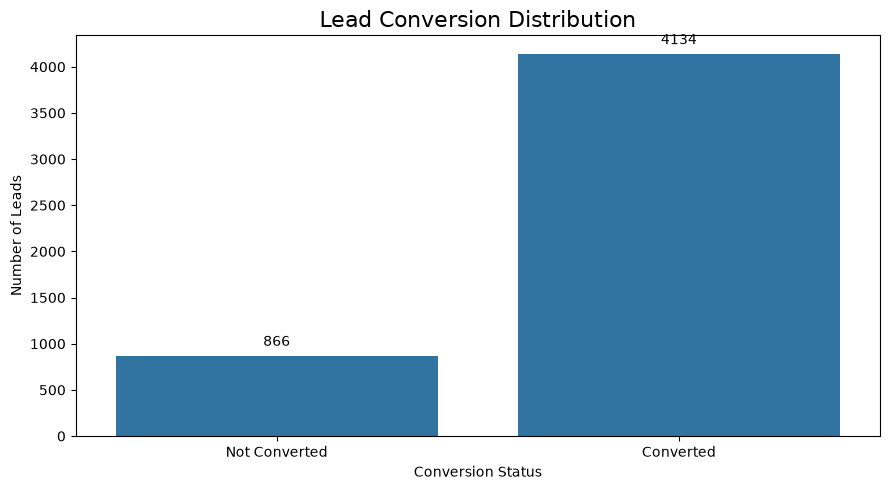

TARGET CLASS PERCENTAGE


,Class,Percentage
0,Not Converted,17.32
1,Converted,82.68


In [6]:

# ==========================================
# 8. TARGET VARIABLE DISTRIBUTION
# ==========================================

target_counts = data["converted"].value_counts().sort_index()

target_labels = ["Not Converted", "Converted"]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=target_labels,
    y=target_counts.values
)

plt.title("Lead Conversion Distribution", fontsize=16)
plt.xlabel("Conversion Status")
plt.ylabel("Number of Leads")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=5)

plt.tight_layout()
plt.show()

# Percentage distribution
target_percentage = (
    data["converted"].value_counts(normalize=True).sort_index() * 100
)

print("TARGET CLASS PERCENTAGE")
display(
    pd.DataFrame({
        "Class": ["Not Converted", "Converted"],
        "Percentage": target_percentage.values.round(2)
    })
)


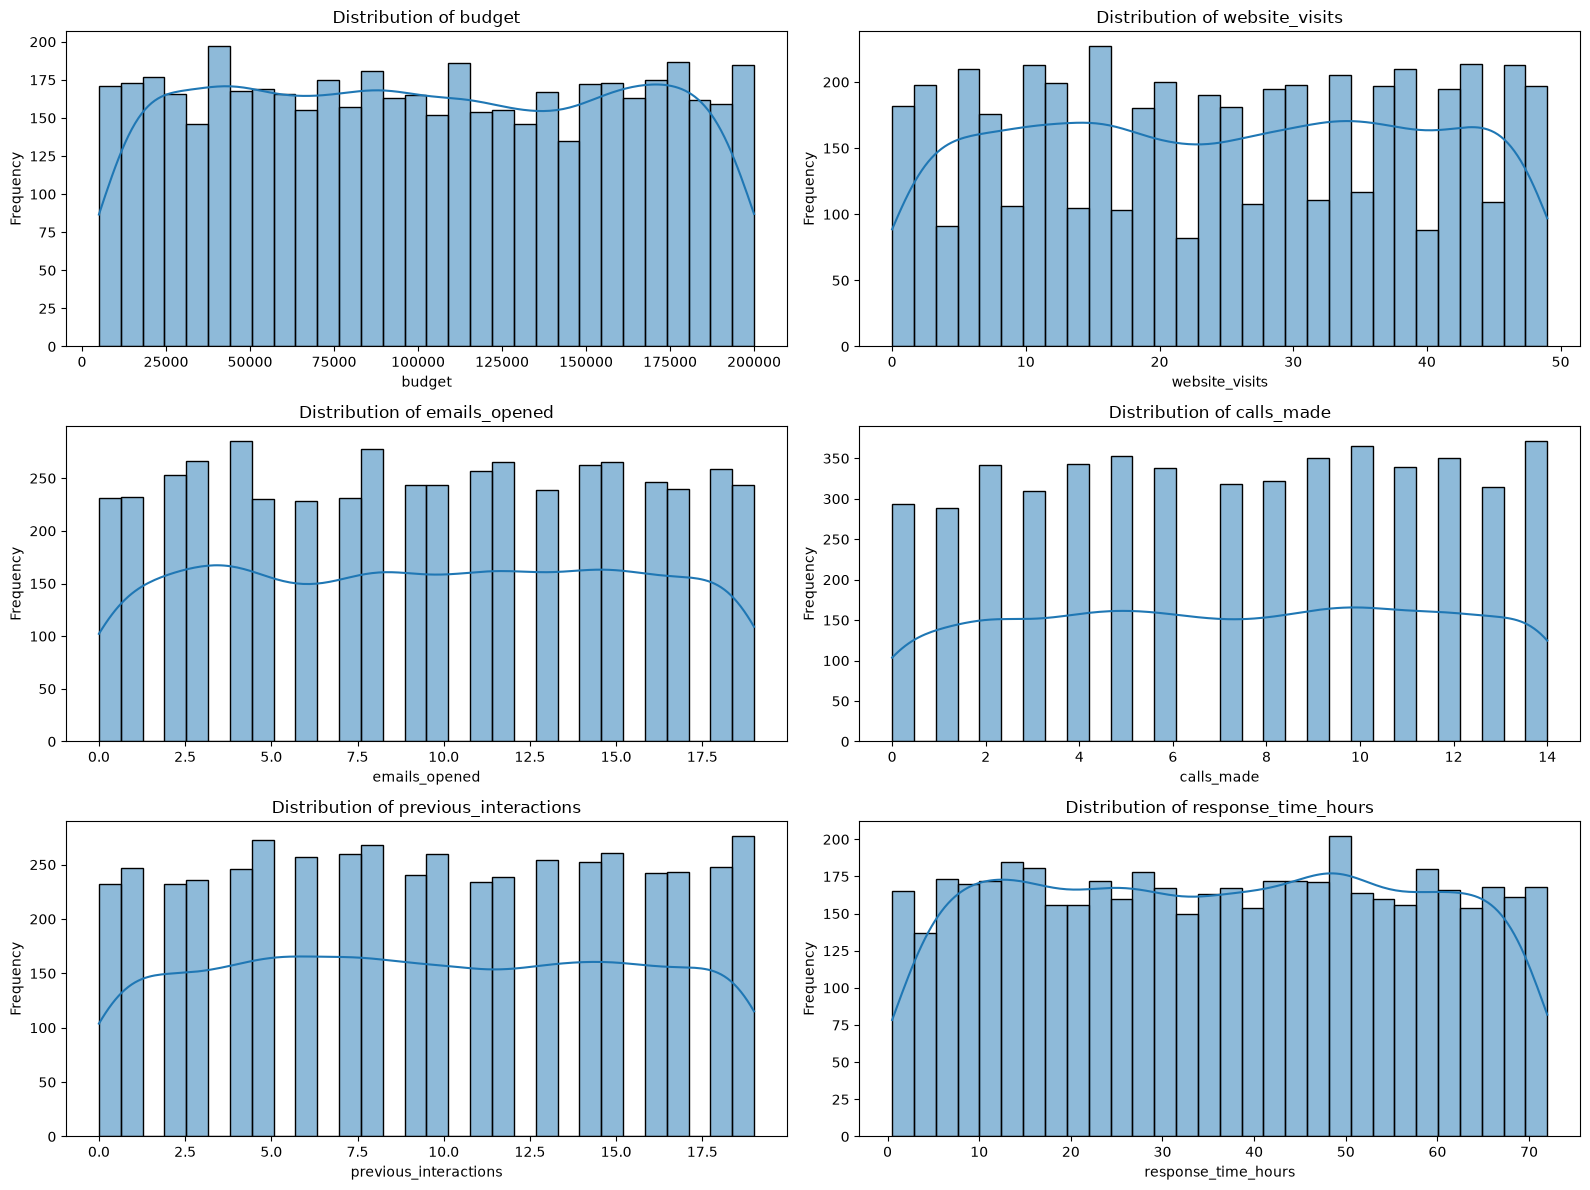

NUMERICAL FEATURE SKEWNESS


,Skewness
budget,0.02
previous_interactions,0.00
response_time_hours,-0.00
emails_opened,-0.01
website_visits,-0.01
calls_made,-0.04


In [7]:

# ==========================================
# 9. NUMERICAL FEATURE DISTRIBUTION
# ==========================================

numerical_features = data.select_dtypes(
    include=["int32", "int64", "float64"]
).columns.drop(["lead_id", "converted"])

plt.figure(figsize=(16, 12))

for i, column in enumerate(numerical_features, 1):

    plt.subplot(3, 2, i)

    sns.histplot(
        data=data,
        x=column,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# Calculate skewness
print("NUMERICAL FEATURE SKEWNESS")

skewness = data[numerical_features].skew()

display(
    skewness.to_frame(name="Skewness").sort_values(
        by="Skewness",
        ascending=False
    )
)



### 9.1 Numerical Feature Distribution — Observations

The numerical feature distributions were analyzed using histograms and KDE curves.

Key findings:

1. Budget is approximately uniformly distributed across its generated range.
2. Website visits, emails opened, calls made, and previous interactions show relatively even distributions.
3. Response time is distributed relatively evenly.
4. All six numerical features have skewness values close to zero.
5. No substantial distribution asymmetry was observed.

### Conclusion

The synthetic numerical features do not currently indicate a need for skewness-based transformations.

However, outlier analysis and feature scaling will be considered during subsequent preprocessing stages.


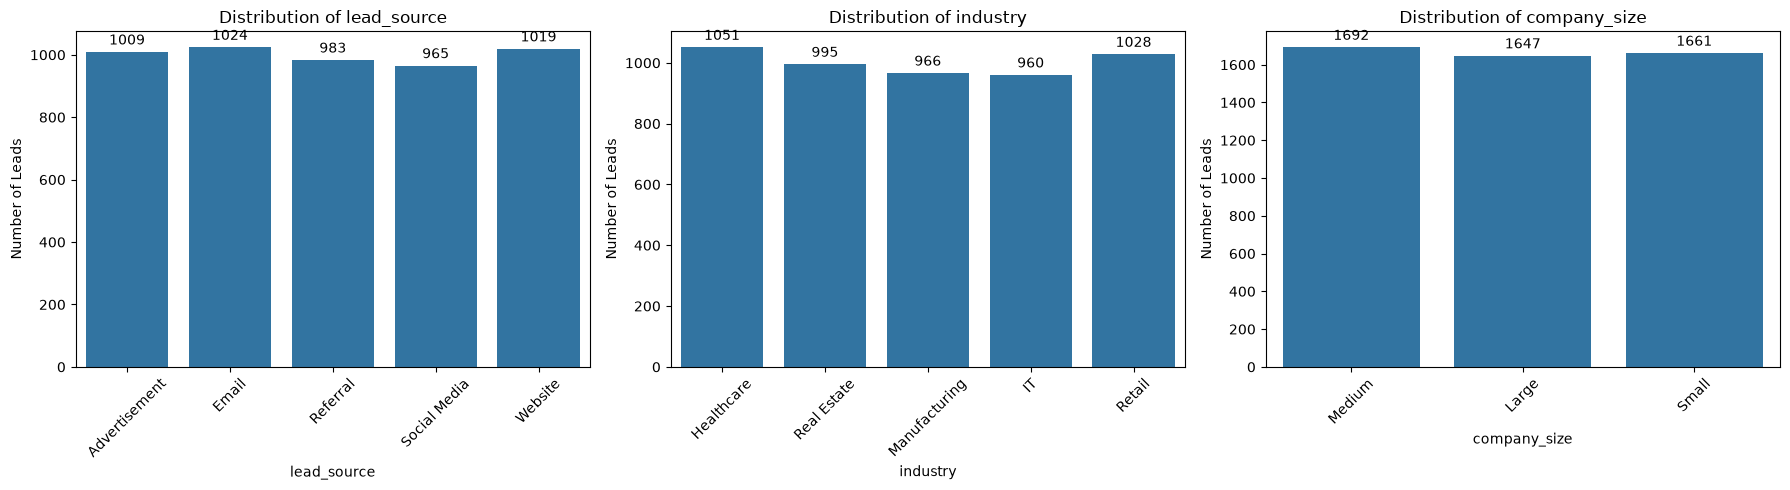


LEAD_SOURCE DISTRIBUTION


,Lead Count
lead_source,
Email,1024
Website,1019
Advertisement,1009
Referral,983
Social Media,965



INDUSTRY DISTRIBUTION


,Lead Count
industry,
Healthcare,1051
Retail,1028
Real Estate,995
Manufacturing,966
IT,960



COMPANY_SIZE DISTRIBUTION


,Lead Count
company_size,
Medium,1692
Small,1661
Large,1647


In [8]:

# ==========================================
# 10. CATEGORICAL FEATURE DISTRIBUTION
# ==========================================

categorical_features = [
    "lead_source",
    "industry",
    "company_size"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, column in enumerate(categorical_features):

    sns.countplot(
        data=data,
        x=column,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of Leads")

    axes[i].tick_params(axis="x", rotation=45)

    for container in axes[i].containers:
        axes[i].bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

# Frequency tables
for column in categorical_features:

    print(f"\n{column.upper()} DISTRIBUTION")

    display(
        data[column]
        .value_counts()
        .to_frame("Lead Count")
    )



### 10.1 Categorical Feature Distribution — Observations

Three categorical features were analyzed.

1. Lead Source:
   All five categories have relatively similar frequencies.

2. Industry:
   The five industries are represented relatively evenly.

3. Company Size:
   Small, Medium and Large companies have approximately equal representation.

### Conclusion

No major categorical frequency imbalance was observed.

One-Hot Encoding will be considered during preprocessing to convert categorical features into numerical representations suitable for machine learning.


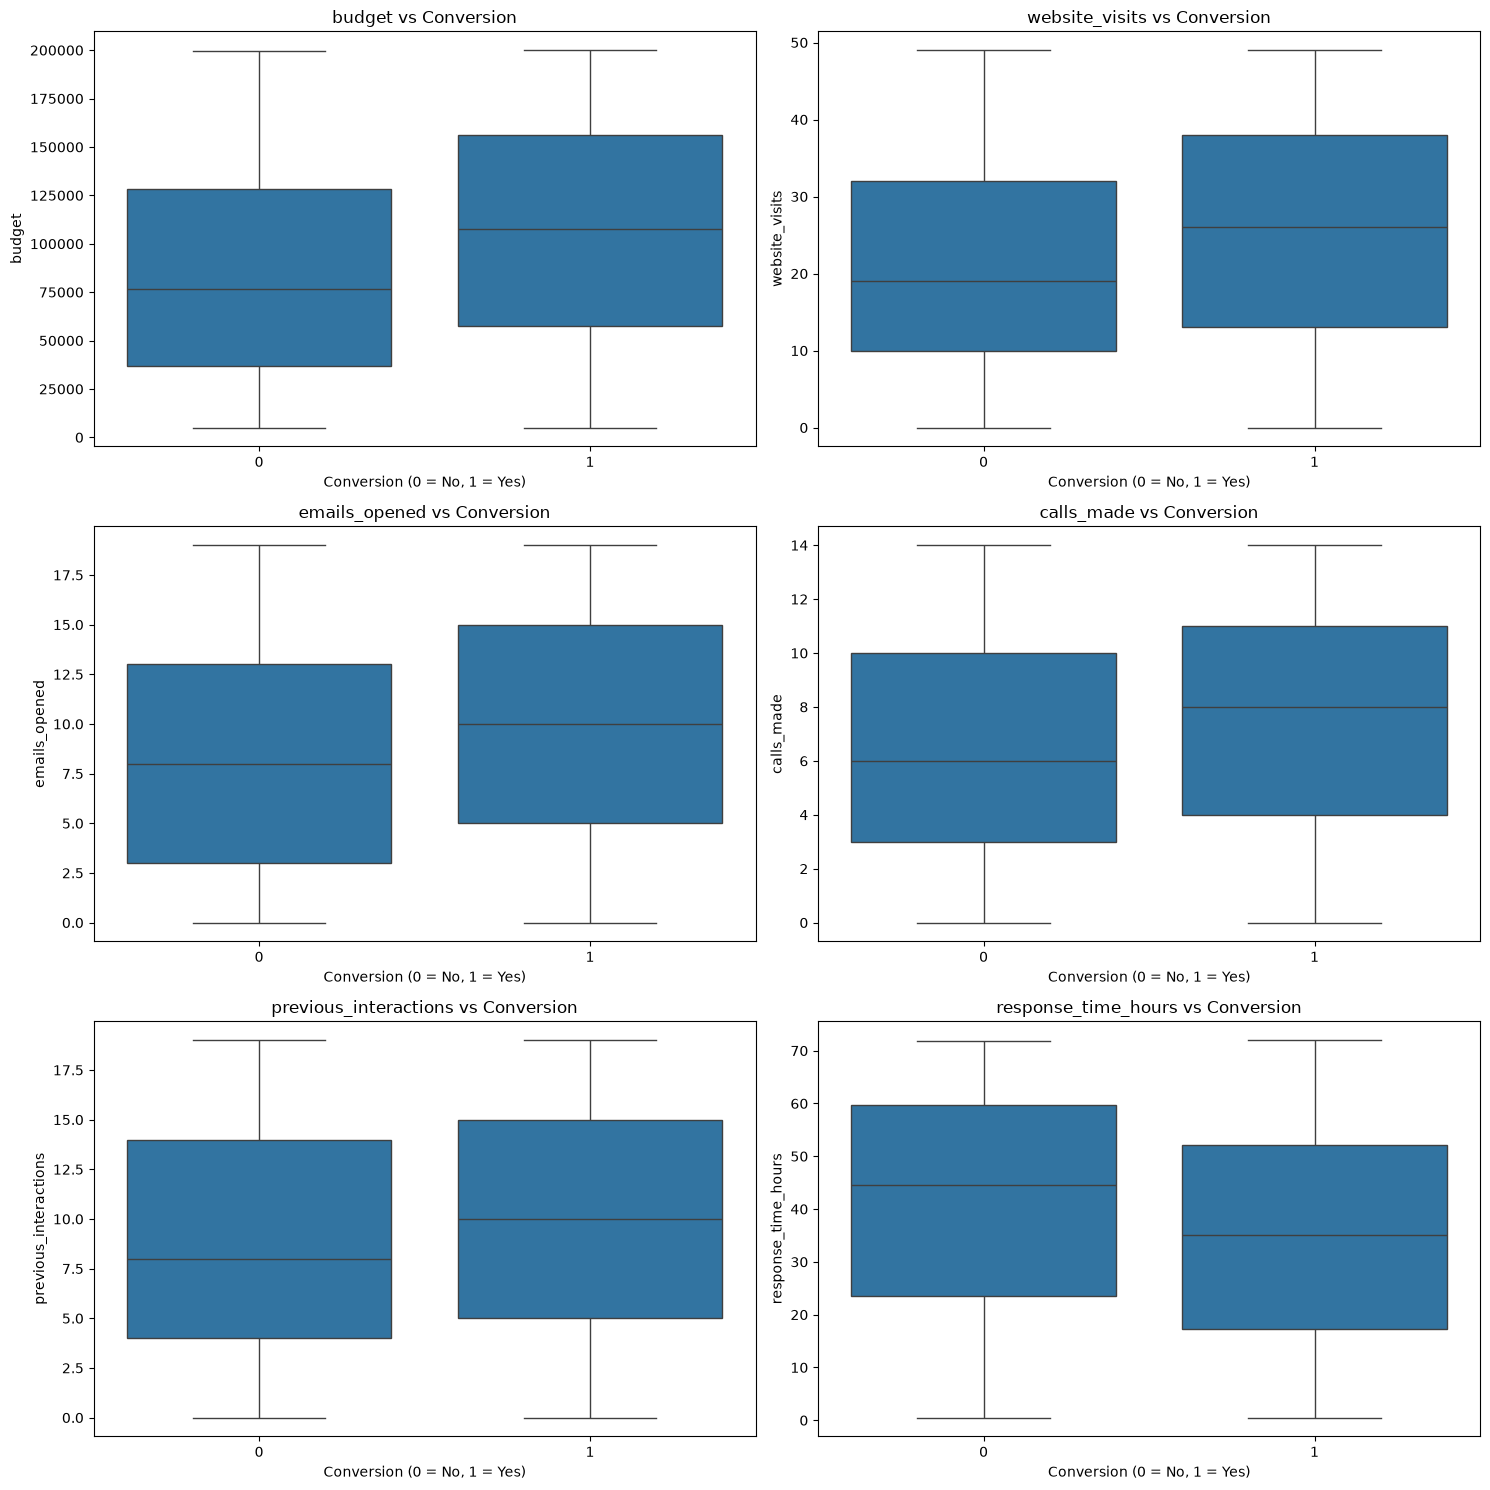

FEATURE AVERAGES BY CONVERSION STATUS


,Not Converted,Converted
budget,83957.10,106090.76
website_visits,21.21,25.50
emails_opened,8.46,9.78
calls_made,6.32,7.36
previous_interactions,9.05,9.70
response_time_hours,41.66,35.16


In [9]:

# ==========================================
# 11. NUMERICAL FEATURES VS CONVERSION
# ==========================================

numerical_features = [
    "budget",
    "website_visits",
    "emails_opened",
    "calls_made",
    "previous_interactions",
    "response_time_hours"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 15))

for i, column in enumerate(numerical_features):

    ax = axes[i // 2, i % 2]

    sns.boxplot(
        data=data,
        x="converted",
        y=column,
        ax=ax
    )

    ax.set_title(f"{column} vs Conversion")
    ax.set_xlabel("Conversion (0 = No, 1 = Yes)")
    ax.set_ylabel(column)

plt.tight_layout()
plt.show()

# Compare average values
print("FEATURE AVERAGES BY CONVERSION STATUS")

conversion_comparison = (
    data.groupby("converted")[numerical_features]
    .mean()
    .T
)

conversion_comparison.columns = [
    "Not Converted",
    "Converted"
]

display(conversion_comparison.round(2))



### 11.1 Numerical Features vs Conversion — Observations

The average numerical feature values were compared between converted and non-converted leads.

Key findings:

1. Converted leads have a higher average budget.
2. Converted leads have more average website visits.
3. Converted leads open more marketing emails.
4. Converted leads have a higher average number of sales calls.
5. Previous interactions show a relatively small difference.
6. Converted leads have a lower average response time.

### Conclusion

Several numerical features show differences between the two conversion groups.

These observations may help identify useful predictive features.

However, correlation and statistical significance must be investigated separately. The dataset is synthetic, so these findings should not be interpreted as verified real-world business relationships.


In [10]:

# ==========================================
# 12. CATEGORICAL FEATURES VS CONVERSION
# ==========================================

categorical_features = [
    "lead_source",
    "industry",
    "company_size"
]

for column in categorical_features:

    print(f"\nCONVERSION RATE BY {column.upper()}")
    print("=" * 55)

    conversion_rate = (
        data.groupby(column)["converted"]
        .agg(["count", "sum", "mean"])
        .rename(columns={
            "count": "Total Leads",
            "sum": "Converted Leads",
            "mean": "Conversion Rate"
        })
    )

    conversion_rate["Conversion Rate"] *= 100

    display(conversion_rate.round(2))



CONVERSION RATE BY LEAD_SOURCE


,Total Leads,Converted Leads,Conversion Rate
lead_source,,,
Advertisement,1009,827,81.96
Email,1024,847,82.71
Referral,983,813,82.71
Social Media,965,799,82.80
Website,1019,848,83.22



CONVERSION RATE BY INDUSTRY


,Total Leads,Converted Leads,Conversion Rate
industry,,,
Healthcare,1051,875,83.25
IT,960,780,81.25
Manufacturing,966,797,82.51
Real Estate,995,815,81.91
Retail,1028,867,84.34



CONVERSION RATE BY COMPANY_SIZE


,Total Leads,Converted Leads,Conversion Rate
company_size,,,
Large,1647,1351,82.03
Medium,1692,1384,81.80
Small,1661,1399,84.23


CORRELATION MATRIX


,budget,website_visits,emails_opened,calls_made,previous_interactions,response_time_hours,converted
budget,1.00,0.00,-0.00,0.03,0.01,-0.01,0.15
website_visits,0.00,1.00,-0.02,0.02,-0.01,-0.00,0.11
emails_opened,-0.00,-0.02,1.00,-0.02,-0.00,-0.00,0.09
calls_made,0.03,0.02,-0.02,1.00,0.02,0.00,0.09
previous_interactions,0.01,-0.01,-0.00,0.02,1.00,-0.00,0.04
response_time_hours,-0.01,-0.00,-0.00,0.00,-0.00,1.00,-0.12
converted,0.15,0.11,0.09,0.09,0.04,-0.12,1.00


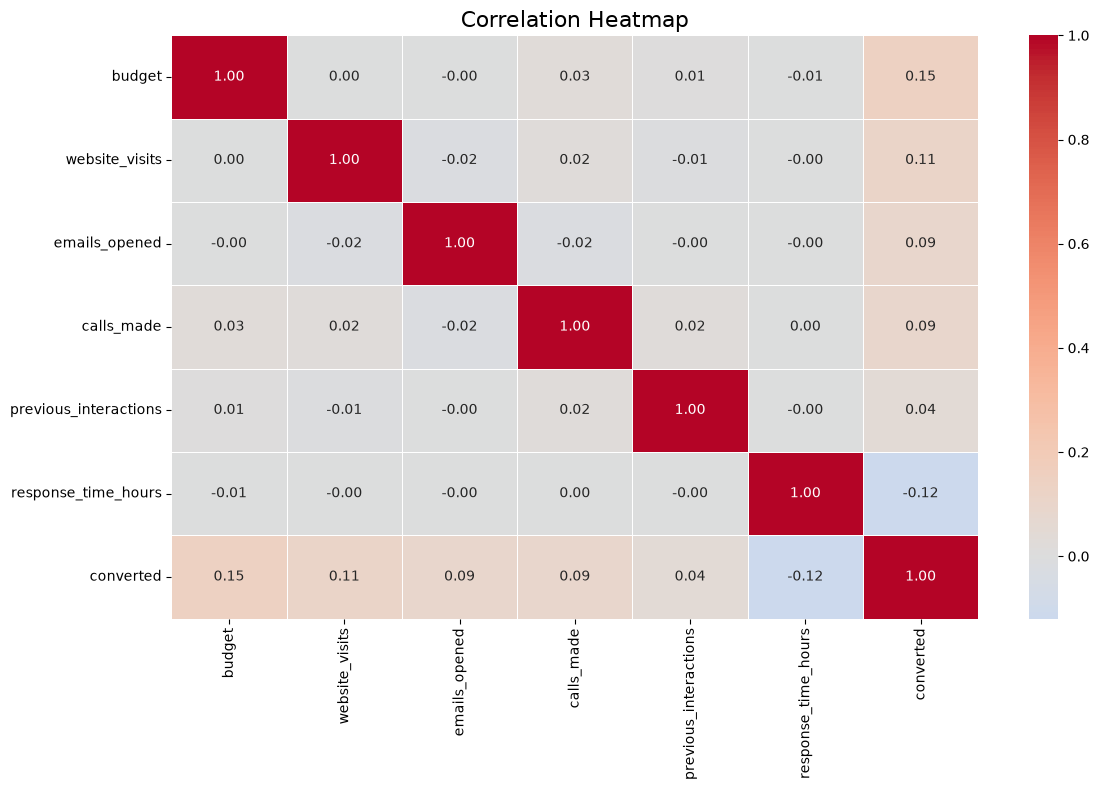

CORRELATION WITH CONVERSION


,Correlation with Conversion
budget,0.15
website_visits,0.11
calls_made,0.09
emails_opened,0.09
previous_interactions,0.04
response_time_hours,-0.12


In [11]:

# ==========================================
# 13. CORRELATION ANALYSIS
# ==========================================

# Select numerical features
correlation_data = data.select_dtypes(
    include=["number"]
).drop(columns=["lead_id"])

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

print("CORRELATION MATRIX")

display(correlation_matrix.round(2))

# Visualize correlation
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

# Correlation with target
print("CORRELATION WITH CONVERSION")

target_correlation = (
    correlation_matrix["converted"]
    .drop("converted")
    .sort_values(ascending=False)
)

display(target_correlation.to_frame("Correlation with Conversion"))



### 13.1 Correlation Analysis — Observations

Pearson correlation analysis was performed on numerical features.

Key findings:

1. Budget has the highest positive correlation with conversion (0.15).
2. Website visits have a weak positive correlation (0.11).
3. Emails opened and calls made have weak positive correlations (0.09 each).
4. Previous interactions have a very weak positive correlation (0.04).
5. Response time has a weak negative correlation (-0.12).
6. Most independent numerical features have correlations close to zero.

### Conclusion

No strong linear relationships were identified between the numerical input features.

No obvious multicollinearity issue is indicated by this correlation matrix.

However, correlation alone cannot determine predictive importance. Further feature evaluation will be performed during model development.


In [12]:

# ==========================================
# 14. OUTLIER DETECTION USING IQR
# ==========================================

numerical_features = [
    "budget",
    "website_visits",
    "emails_opened",
    "calls_made",
    "previous_interactions",
    "response_time_hours"
]

outlier_results = []

for column in numerical_features:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,budget,52436.44,153053.00,100616.56,-98488.40,303977.84,0
1,website_visits,12.00,37.00,25.00,-25.50,74.50,0
2,emails_opened,4.00,15.00,11.00,-12.50,31.50,0
3,calls_made,4.00,11.00,7.00,-6.50,21.50,0
4,previous_interactions,5.00,15.00,10.00,-10.00,30.00,0
5,response_time_hours,18.19,53.68,35.49,-35.05,106.92,0



### 14.1 Outlier Detection — Observations

The Interquartile Range (IQR) method was used to detect outliers in six numerical features.

Results:

1. Budget: 0 outliers.
2. Website visits: 0 outliers.
3. Emails opened: 0 outliers.
4. Calls made: 0 outliers.
5. Previous interactions: 0 outliers.
6. Response time: 0 outliers.

### Conclusion

No observations exceeded the 1.5 × IQR boundaries.

Therefore, no IQR-based outlier removal or treatment is currently required for this synthetic dataset.

This conclusion is specific to the generated dataset and does not guarantee that real business data will contain no outliers.


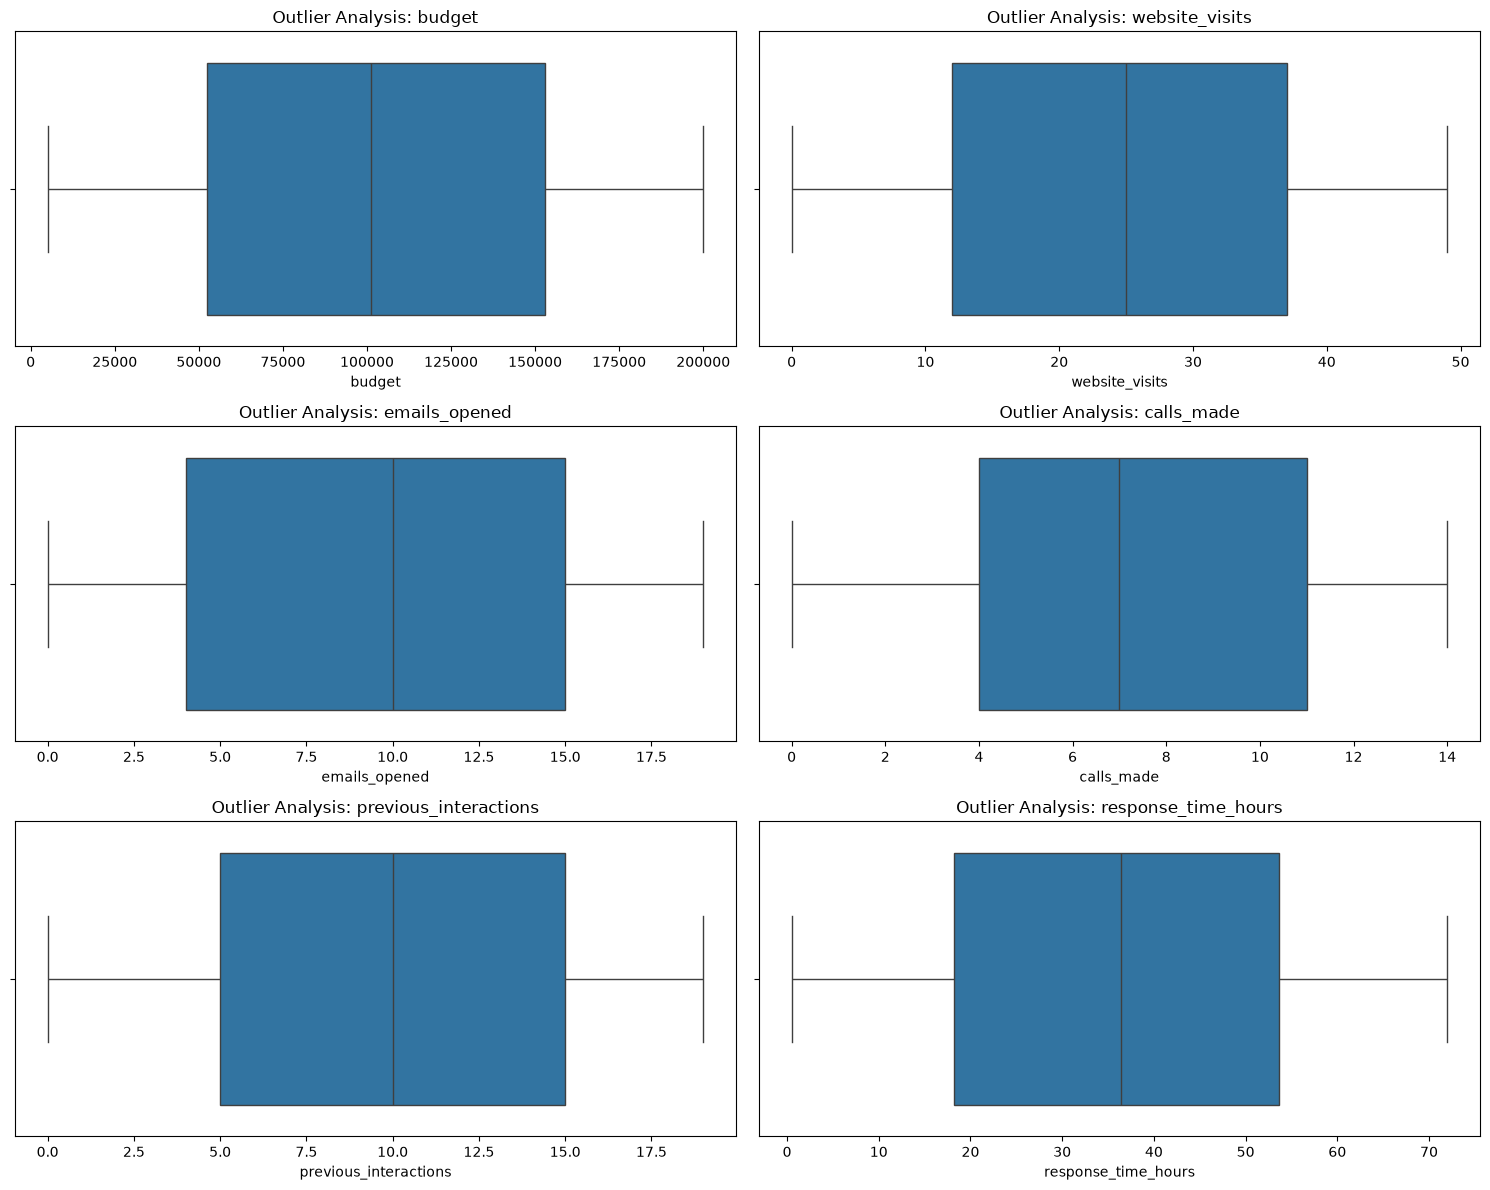

In [13]:

# ==========================================
# 15. OUTLIER VISUALIZATION USING BOXPLOTS
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, column in enumerate(numerical_features):

    ax = axes[i // 2, i % 2]

    sns.boxplot(
        data=data,
        x=column,
        ax=ax
    )

    ax.set_title(f"Outlier Analysis: {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()




### 15.1 Boxplot Analysis — Observations

Boxplots were generated for all six numerical features.

Key findings:

1. Budget shows a wide range of values.
2. Website visits have a median of approximately 25.
3. Emails opened have a median of approximately 10.
4. Calls made have a median of approximately 7.
5. Previous interactions have a median of approximately 10.
6. Response time has a median of approximately 36 hours.

### Conclusion

No individual outlier points were visibly identified in the six boxplots.

These visual findings support the earlier IQR analysis, which detected zero outliers.

No outlier removal is currently required for this synthetic dataset.


In [14]:

# ==========================================
# 16. SAVE RAW DATASET
# ==========================================

# Ensure raw data directory exists
os.makedirs(DATA_RAW, exist_ok=True)

# Save dataset
raw_data_path = os.path.join(
    DATA_RAW,
    "sales_leads_raw.csv"
)

data.to_csv(
    raw_data_path,
    index=False
)

print("Dataset saved successfully!")
print("File location:", raw_data_path)

# Verify saved file
print("\nSaved file exists:", os.path.exists(raw_data_path))

print("Saved file size:",
      round(os.path.getsize(raw_data_path) / 1024, 2),
      "KB")


Dataset saved successfully!
File location: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\data\raw\sales_leads_raw.csv

Saved file exists: True
Saved file size: 287.32 KB


In [15]:

# ==========================================
# 17. VERIFY SAVED DATASET
# ==========================================

# Load saved CSV
loaded_data = pd.read_csv(raw_data_path)

print("DATASET LOADED SUCCESSFULLY")

print("\nOriginal dataset shape:", data.shape)
print("Loaded dataset shape:", loaded_data.shape)

print("\nFirst five records:")
display(loaded_data.head())

# Compare original and loaded datasets
print("\nDATASET VALIDATION")

print(
    "Both datasets have identical values:",
    data.equals(loaded_data)
)

print(
    "Both datasets have identical columns:",
    data.columns.equals(loaded_data.columns)
)


DATASET LOADED SUCCESSFULLY

Original dataset shape: (5000, 11)
Loaded dataset shape: (5000, 11)

First five records:


,lead_id,lead_source,industry,company_size,budget,website_visits,emails_opened,calls_made,previous_interactions,response_time_hours,converted
0,1,Advertisement,Healthcare,Medium,167628.20,33,0,14,16,7.56,1
1,2,Email,Real Estate,Medium,32355.58,25,19,12,11,48.94,1
2,3,Referral,Manufacturing,Large,177880.00,0,1,1,5,40.74,1
3,4,Email,Manufacturing,Small,147305.66,35,6,14,11,62.21,1
4,5,Email,Real Estate,Large,37110.70,43,15,3,14,44.06,1



DATASET VALIDATION
Both datasets have identical values: False
Both datasets have identical columns: True


In [16]:

# ==========================================
# 17.1 DEBUG DATASET VALIDATION
# ==========================================

print("ORIGINAL DATA TYPES")
display(data.dtypes.to_frame("Original"))

print("\nLOADED DATA TYPES")
display(loaded_data.dtypes.to_frame("Loaded"))

print("\nDATA TYPE COMPARISON")

dtype_comparison = pd.DataFrame({
    "Original": data.dtypes.astype(str),
    "Loaded": loaded_data.dtypes.astype(str)
})

display(dtype_comparison)

print("\nNUMERICAL VALUE COMPARISON")

for column in data.select_dtypes(include="number").columns:

    print(
        column,
        "Identical:",
        np.array_equal(
            data[column].to_numpy(),
            loaded_data[column].to_numpy()
        )
    )


ORIGINAL DATA TYPES


,Original
lead_id,int64
lead_source,str
industry,str
company_size,str
budget,float64
website_visits,int32
emails_opened,int32
calls_made,int32
previous_interactions,int32
response_time_hours,float64



LOADED DATA TYPES


,Loaded
lead_id,int64
lead_source,str
industry,str
company_size,str
budget,float64
website_visits,int64
emails_opened,int64
calls_made,int64
previous_interactions,int64
response_time_hours,float64



DATA TYPE COMPARISON


,Original,Loaded
lead_id,int64,int64
lead_source,str,str
industry,str,str
company_size,str,str
budget,float64,float64
website_visits,int32,int64
emails_opened,int32,int64
calls_made,int32,int64
previous_interactions,int32,int64
response_time_hours,float64,float64



NUMERICAL VALUE COMPARISON
lead_id Identical: True
budget Identical: True
website_visits Identical: True
emails_opened Identical: True
calls_made Identical: True
previous_interactions Identical: True
response_time_hours Identical: True
converted Identical: True


In [17]:

# ==========================================
# 17.2 FIX DATA TYPES
# ==========================================

integer_columns = [
    "website_visits",
    "emails_opened",
    "calls_made",
    "previous_interactions",
    "converted"
]

for column in integer_columns:
    loaded_data[column] = loaded_data[column].astype("int32")

print("DATA TYPES AFTER CONVERSION")

display(
    pd.DataFrame({
        "Original": data.dtypes.astype(str),
        "Loaded": loaded_data.dtypes.astype(str)
    })
)

print("\nFINAL DATASET VALIDATION")

print(
    "Identical values and data types:",
    data.equals(loaded_data)
)


DATA TYPES AFTER CONVERSION


,Original,Loaded
lead_id,int64,int64
lead_source,str,str
industry,str,str
company_size,str,str
budget,float64,float64
website_visits,int32,int32
emails_opened,int32,int32
calls_made,int32,int32
previous_interactions,int32,int32
response_time_hours,float64,float64



FINAL DATASET VALIDATION
Identical values and data types: True


In [18]:
data_quality_report = pd.DataFrame({
    "Data Type": data.dtypes.astype(str),
    "Missing Values": data.isnull().sum(),
    "Unique Values": data.nunique(),
    "Duplicate Values": data.duplicated().sum()
})

display(data_quality_report)

print("Total Rows:", data.shape[0])
print("Total Columns:", data.shape[1])
print("Total Missing Values:", data.isnull().sum().sum())
print("Total Duplicate Rows:", data.duplicated().sum())

,Data Type,Missing Values,Unique Values,Duplicate Values
lead_id,int64,0,5000,0
lead_source,str,0,5,0
industry,str,0,5,0
company_size,str,0,3,0
budget,float64,0,4999,0
website_visits,int32,0,50,0
emails_opened,int32,0,20,0
calls_made,int32,0,15,0
previous_interactions,int32,0,20,0
response_time_hours,float64,0,3628,0


Total Rows: 5000
Total Columns: 11
Total Missing Values: 0
Total Duplicate Rows: 0


In [19]:
# Separate input features and target variable

X = data.drop(
    columns=["lead_id", "converted"]
)

y = data["converted"]

print("FEATURE MATRIX (X)")
print("Shape:", X.shape)
display(X.head())

print("\nTARGET VARIABLE (y)")
print("Shape:", y.shape)
display(y.head())

print("\nTARGET DISTRIBUTION")
print(y.value_counts())

FEATURE MATRIX (X)
Shape: (5000, 9)


,lead_source,industry,company_size,budget,website_visits,emails_opened,calls_made,previous_interactions,response_time_hours
0,Advertisement,Healthcare,Medium,167628.20,33,0,14,16,7.56
1,Email,Real Estate,Medium,32355.58,25,19,12,11,48.94
2,Referral,Manufacturing,Large,177880.00,0,1,1,5,40.74
3,Email,Manufacturing,Small,147305.66,35,6,14,11,62.21
4,Email,Real Estate,Large,37110.70,43,15,3,14,44.06



TARGET VARIABLE (y)
Shape: (5000,)


0    1
1    1
2    1
3    1
4    1
Name: converted, dtype: int32


TARGET DISTRIBUTION
converted
1    4134
0     866
Name: count, dtype: int64


In [20]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=["int32", "int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("NUMERICAL FEATURES")
print(numerical_features)

print("\nCATEGORICAL FEATURES")
print(categorical_features)

print("\nFEATURE COUNT")
print("Numerical:", len(numerical_features))
print("Categorical:", len(categorical_features))
print("Total:", len(numerical_features) + len(categorical_features))

NUMERICAL FEATURES
['budget', 'website_visits', 'emails_opened', 'calls_made', 'previous_interactions', 'response_time_hours']

CATEGORICAL FEATURES
['lead_source', 'industry', 'company_size']

FEATURE COUNT
Numerical: 6
Categorical: 3
Total: 9


## Feature Availability and Data Leakage Review

The model is intended to predict the likelihood of a lead converting.

Before using each feature, we must establish whether its value is available at the exact prediction time.

Potentially time-dependent features:
- website_visits
- emails_opened
- calls_made
- previous_interactions
- response_time_hours

These features must represent information collected before the prediction timestamp.

The synthetic dataset does not currently contain a prediction timestamp.
Therefore, the dataset is suitable for pipeline development, but its predictive performance should not be treated as proof of real-world business performance.

## Preprocessing Strategy

### Numerical Features
- Missing value handling: SimpleImputer(strategy="median")
- Scaling: StandardScaler

### Categorical Features
- Missing value handling: SimpleImputer(strategy="most_frequent")
- Encoding: OneHotEncoder(handle_unknown="ignore")

### Pipeline Architecture

Numerical Features:
SimpleImputer → StandardScaler

Categorical Features:
SimpleImputer → OneHotEncoder

Both transformations:
ColumnTransformer → Machine Learning Model

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Numerical preprocessing pipeline

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created successfully!")

print(numerical_pipeline)

Numerical preprocessing pipeline created successfully!
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [22]:
from sklearn.preprocessing import OneHotEncoder

# Categorical preprocessing pipeline

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

print("Categorical preprocessing pipeline created successfully!")

print(categorical_pipeline)

Categorical preprocessing pipeline created successfully!
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])


In [23]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Combined preprocessor created successfully!")
print(preprocessor)

Combined preprocessor created successfully!
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['budget', 'website_visits', 'emails_opened',
                                  'calls_made', 'previous_interactions',
                                  'response_time_hours']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['lead_source', 'industry', 'company_size'])])


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAINING DATA")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTESTING DATA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTRAINING TARGET DISTRIBUTION")
print(y_train.value_counts(normalize=True) * 100)

print("\nTESTING TARGET DISTRIBUTION")
print(y_test.value_counts(normalize=True) * 100)

TRAINING DATA
X_train: (4000, 9)
y_train: (4000,)

TESTING DATA
X_test: (1000, 9)
y_test: (1000,)

TRAINING TARGET DISTRIBUTION
converted
1   82.67
0   17.32
Name: proportion, dtype: float64

TESTING TARGET DISTRIBUTION
converted
1   82.70
0   17.30
Name: proportion, dtype: float64


In [25]:
# Fit preprocessing on training data only

X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSING COMPLETED")

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nPreprocessing fitted using training data only.")

PREPROCESSING COMPLETED
Original training shape: (4000, 9)
Processed training shape: (4000, 19)

Original testing shape: (1000, 9)
Processed testing shape: (1000, 19)

Preprocessing fitted using training data only.


In [26]:
# Get transformed feature names

transformed_feature_names = preprocessor.get_feature_names_out()

print("TOTAL TRANSFORMED FEATURES:",
      len(transformed_feature_names))

print("\nTRANSFORMED FEATURE NAMES:")

for index, feature in enumerate(transformed_feature_names, start=1):
    print(f"{index}. {feature}")

TOTAL TRANSFORMED FEATURES: 19

TRANSFORMED FEATURE NAMES:
1. num__budget
2. num__website_visits
3. num__emails_opened
4. num__calls_made
5. num__previous_interactions
6. num__response_time_hours
7. cat__lead_source_Advertisement
8. cat__lead_source_Email
9. cat__lead_source_Referral
10. cat__lead_source_Social Media
11. cat__lead_source_Website
12. cat__industry_Healthcare
13. cat__industry_IT
14. cat__industry_Manufacturing
15. cat__industry_Real Estate
16. cat__industry_Retail
17. cat__company_size_Large
18. cat__company_size_Medium
19. cat__company_size_Small


In [27]:
# Convert processed training data into DataFrame

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=transformed_feature_names,
    index=X_train.index
)

print("PROCESSED TRAINING DATA")

print("Shape:", X_train_processed_df.shape)

display(X_train_processed_df.head())

print("\nDATA TYPES")

print(X_train_processed_df.dtypes)

print("\nMISSING VALUES")

print(X_train_processed_df.isnull().sum().sum())

PROCESSED TRAINING DATA
Shape: (4000, 19)


,num__budget,num__website_visits,num__emails_opened,num__calls_made,num__previous_interactions,num__response_time_hours,cat__lead_source_Advertisement,cat__lead_source_Email,cat__lead_source_Referral,cat__lead_source_Social Media,cat__lead_source_Website,cat__industry_Healthcare,cat__industry_IT,cat__industry_Manufacturing,cat__industry_Real Estate,cat__industry_Retail,cat__company_size_Large,cat__company_size_Medium,cat__company_size_Small
1094,0.61,-0.88,0.96,-1.21,-0.80,-0.64,0.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
4306,0.22,-1.72,0.78,-1.21,-1.67,-0.46,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00
1119,-0.66,1.06,-0.45,0.65,1.30,0.05,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00
128,1.38,0.85,-1.32,-0.75,-1.50,-1.30,0.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
311,1.10,-0.61,-0.62,0.42,0.60,-0.20,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00



DATA TYPES
num__budget                       float64
num__website_visits               float64
num__emails_opened                float64
num__calls_made                   float64
num__previous_interactions        float64
num__response_time_hours          float64
cat__lead_source_Advertisement    float64
cat__lead_source_Email            float64
cat__lead_source_Referral         float64
cat__lead_source_Social Media     float64
cat__lead_source_Website          float64
cat__industry_Healthcare          float64
cat__industry_IT                  float64
cat__industry_Manufacturing       float64
cat__industry_Real Estate         float64
cat__industry_Retail              float64
cat__company_size_Large           float64
cat__company_size_Medium          float64
cat__company_size_Small           float64
dtype: object

MISSING VALUES
0


In [28]:
# Verify numerical feature scaling

scaled_numerical_columns = [
    "num__budget",
    "num__website_visits",
    "num__emails_opened",
    "num__calls_made",
    "num__previous_interactions",
    "num__response_time_hours"
]

scaling_report = pd.DataFrame({
    "Mean": X_train_processed_df[scaled_numerical_columns].mean(),
    "Standard Deviation": X_train_processed_df[scaled_numerical_columns].std(ddof=0)
})

display(scaling_report.round(4))

,Mean,Standard Deviation
num__budget,0.00,1.00
num__website_visits,-0.00,1.00
num__emails_opened,0.00,1.00
num__calls_made,-0.00,1.00
num__previous_interactions,0.00,1.00
num__response_time_hours,-0.00,1.00


In [29]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train baseline model
baseline_model.fit(X_train_processed, y_train)

# Generate test predictions
baseline_predictions = baseline_model.predict(X_test_processed)

# Evaluate baseline
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("BASELINE MODEL RESULTS")
print("Accuracy:", round(baseline_accuracy, 4))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        baseline_predictions,
        zero_division=0
    )
)

BASELINE MODEL RESULTS
Accuracy: 0.827

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       173
           1       0.83      1.00      0.91       827

    accuracy                           0.83      1000
   macro avg       0.41      0.50      0.45      1000
weighted avg       0.68      0.83      0.75      1000



In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

# Predict test data
logistic_predictions = logistic_model.predict(X_test_processed)

# Evaluate model
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("LOGISTIC REGRESSION RESULTS")
print("Accuracy:", round(logistic_accuracy, 4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

print("\nCONFUSION MATRIX")

print(confusion_matrix(y_test, logistic_predictions))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.825

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.33      0.01      0.02       173
           1       0.83      1.00      0.90       827

    accuracy                           0.82      1000
   macro avg       0.58      0.50      0.46      1000
weighted avg       0.74      0.82      0.75      1000


CONFUSION MATRIX
[[  2 171]
 [  4 823]]


In [31]:
# Get predicted probabilities

logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)

# Create probability analysis DataFrame

probability_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": logistic_predictions,
    "Probability_Not_Converted": logistic_probabilities[:, 0],
    "Probability_Converted": logistic_probabilities[:, 1]
})

print("PREDICTION PROBABILITY ANALYSIS")

display(probability_analysis.head(10))

print("\nPROBABILITY SUMMARY")

display(
    probability_analysis[
        ["Probability_Not_Converted", "Probability_Converted"]
    ].describe().round(4)
)

PREDICTION PROBABILITY ANALYSIS


,Actual,Predicted,Probability_Not_Converted,Probability_Converted
1832,1,1,0.09,0.91
1700,1,1,0.18,0.82
1224,0,1,0.27,0.73
2834,0,1,0.26,0.74
3373,1,1,0.12,0.88
2974,0,1,0.13,0.87
1502,1,1,0.23,0.77
4136,1,1,0.03,0.97
2177,1,1,0.18,0.82
4356,1,1,0.14,0.86



PROBABILITY SUMMARY


,Probability_Not_Converted,Probability_Converted
count,1000.00,1000.00
mean,0.17,0.83
std,0.10,0.10
min,0.02,0.46
25%,0.10,0.77
50%,0.15,0.85
75%,0.23,0.90
max,0.54,0.98


In [32]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

thresholds = [0.50, 0.40, 0.30, 0.20, 0.10]

threshold_results = []

# Probability of class 1 (converted)
conversion_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

for threshold in thresholds:

    # Apply threshold
    predictions = (
        conversion_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Class_0_Precision": precision_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Class_0_Recall": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Class_0_F1": f1_score(
            y_test, predictions, pos_label=0, zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

,Threshold,Accuracy,Class_0_Precision,Class_0_Recall,Class_0_F1
0,0.50,0.82,0.33,0.01,0.02
1,0.40,0.83,0.00,0.00,0.00
2,0.30,0.83,0.00,0.00,0.00
3,0.20,0.83,0.00,0.00,0.00
4,0.10,0.83,0.00,0.00,0.00


In [33]:
thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85]

threshold_results = []

for threshold in thresholds:

    predictions = (
        conversion_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Class_0_Precision": precision_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Class_0_Recall": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Class_0_F1": f1_score(
            y_test, predictions, pos_label=0, zero_division=0
        )
    })

higher_threshold_results = pd.DataFrame(threshold_results)

display(higher_threshold_results.round(4))

,Threshold,Accuracy,Class_0_Precision,Class_0_Recall,Class_0_F1
0,0.50,0.82,0.33,0.01,0.02
1,0.55,0.83,0.47,0.04,0.07
2,0.60,0.82,0.47,0.11,0.18
3,0.65,0.81,0.37,0.16,0.22
4,0.70,0.79,0.34,0.24,0.28
5,0.75,0.75,0.30,0.34,0.32
6,0.80,0.68,0.28,0.54,0.36
7,0.85,0.56,0.23,0.66,0.34


AVERAGE PRECISION: 0.8952


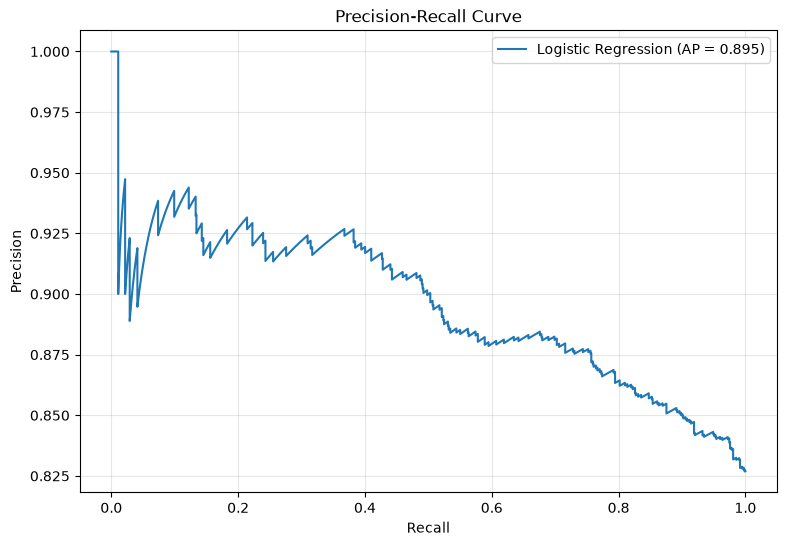

In [34]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Calculate precision and recall at different thresholds

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_test,
        conversion_probabilities
    )
)

# Calculate Average Precision
average_precision = average_precision_score(
    y_test,
    conversion_probabilities
)

print("AVERAGE PRECISION:", round(average_precision, 4))

# Plot Precision-Recall curve

plt.figure(figsize=(9, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Logistic Regression (AP = {average_precision:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

CLASS 0 AVERAGE PRECISION: 0.2913


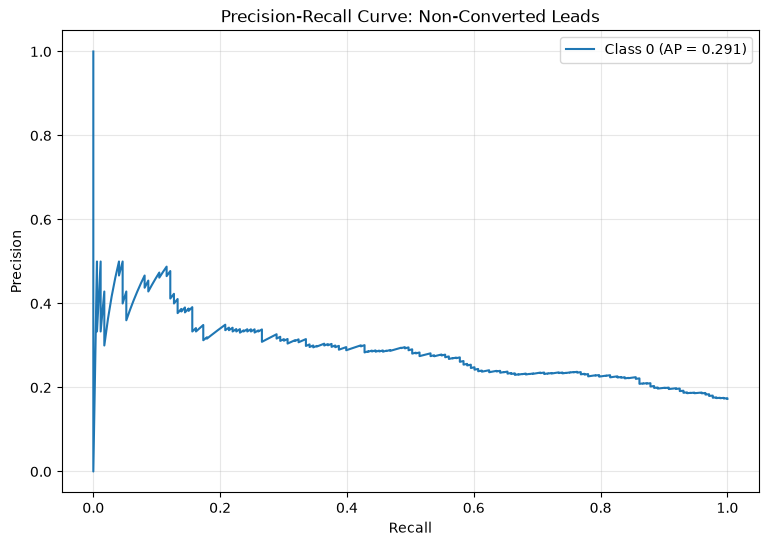

In [35]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Probability of not converting (class 0)
not_converted_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 0]

# Calculate precision and recall for class 0
precision_0, recall_0, thresholds_0 = precision_recall_curve(
    (y_test == 0).astype(int),
    not_converted_probabilities
)

# Calculate Average Precision for class 0
average_precision_0 = average_precision_score(
    (y_test == 0).astype(int),
    not_converted_probabilities
)

print(
    "CLASS 0 AVERAGE PRECISION:",
    round(average_precision_0, 4)
)

# Plot Precision-Recall curve
plt.figure(figsize=(9, 6))

plt.plot(
    recall_0,
    precision_0,
    label=f"Class 0 (AP = {average_precision_0:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: Non-Converted Leads")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [36]:
from sklearn.model_selection import train_test_split

# Split training data into training and validation sets

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("MODEL TRAINING DATA")
print("X_train_final:", X_train_final.shape)
print("y_train_final:", y_train_final.shape)

print("\nVALIDATION DATA")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nFINAL TEST DATA (RESERVED)")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

MODEL TRAINING DATA
X_train_final: (3200, 9)
y_train_final: (3200,)

VALIDATION DATA
X_val: (800, 9)
y_val: (800,)

FINAL TEST DATA (RESERVED)
X_test: (1000, 9)
y_test: (1000,)


In [37]:
# Fit preprocessing using training partition only

X_train_final_processed = preprocessor.fit_transform(
    X_train_final
)

# Transform validation data
X_val_processed = preprocessor.transform(X_val)

# Transform reserved test data
X_test_final_processed = preprocessor.transform(X_test)

print("PREPROCESSING VALIDATION")

print("Training:", X_train_final_processed.shape)
print("Validation:", X_val_processed.shape)
print("Final Test:", X_test_final_processed.shape)


PREPROCESSING VALIDATION
Training: (3200, 19)
Validation: (800, 19)
Final Test: (1000, 19)


In [38]:
# Create a fresh Logistic Regression model

logistic_model_v2 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using training data only

logistic_model_v2.fit(
    X_train_final_processed,
    y_train_final
)

print("LOGISTIC REGRESSION V2 TRAINED SUCCESSFULLY")

print("Training records:", len(y_train_final))
print("Number of features:", X_train_final_processed.shape[1])

LOGISTIC REGRESSION V2 TRAINED SUCCESSFULLY
Training records: 3200
Number of features: 19


In [39]:
# Predict conversion probabilities on validation data

val_probabilities = logistic_model_v2.predict_proba(
    X_val_processed
)

# Create validation results DataFrame

validation_results = pd.DataFrame({
    "Actual": y_val,
    "Probability_Not_Converted": val_probabilities[:, 0],
    "Probability_Converted": val_probabilities[:, 1]
})

print("VALIDATION PROBABILITY ANALYSIS")

display(validation_results.head(10))

print("\nPROBABILITY SUMMARY")

display(
    validation_results[
        ["Probability_Not_Converted", "Probability_Converted"]
    ].describe().round(4)
)

VALIDATION PROBABILITY ANALYSIS


,Actual,Probability_Not_Converted,Probability_Converted
82,1,0.24,0.76
2139,1,0.10,0.90
3622,0,0.19,0.81
167,1,0.13,0.87
4367,1,0.12,0.88
4315,1,0.14,0.86
4477,1,0.13,0.87
662,1,0.09,0.91
2383,1,0.12,0.88
4324,1,0.15,0.85



PROBABILITY SUMMARY


,Probability_Not_Converted,Probability_Converted
count,800.00,800.00
mean,0.17,0.83
std,0.10,0.10
min,0.02,0.38
25%,0.10,0.77
50%,0.15,0.85
75%,0.23,0.90
max,0.62,0.98


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

validation_conversion_probabilities = val_probabilities[:, 1]

thresholds = [
    0.50, 0.55, 0.60, 0.65, 0.70,
    0.75, 0.80, 0.85, 0.90
]

validation_threshold_results = []

for threshold in thresholds:

    predictions = (
        validation_conversion_probabilities >= threshold
    ).astype(int)

    validation_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Class_0_Precision": precision_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Class_0_Recall": recall_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Class_0_F1": f1_score(
            y_val, predictions, pos_label=0, zero_division=0
        )
    })

validation_threshold_df = pd.DataFrame(
    validation_threshold_results
)

display(validation_threshold_df.round(4))

,Threshold,Accuracy,Class_0_Precision,Class_0_Recall,Class_0_F1
0,0.50,0.83,0.57,0.03,0.05
1,0.55,0.83,0.50,0.06,0.10
2,0.60,0.83,0.53,0.12,0.19
3,0.65,0.82,0.46,0.19,0.27
4,0.70,0.80,0.38,0.29,0.33
5,0.75,0.77,0.35,0.42,0.38
6,0.80,0.69,0.29,0.55,0.38
7,0.85,0.58,0.25,0.71,0.37
8,0.90,0.40,0.21,0.87,0.33


In [41]:
# Select threshold using validation results

selected_threshold = 0.75

print("SELECTED CLASSIFICATION THRESHOLD")
print(selected_threshold)

# Generate validation predictions
validation_predictions_final = (
    validation_conversion_probabilities >= selected_threshold
).astype(int)

print("\nVALIDATION PERFORMANCE")

print(
    classification_report(
        y_val,
        validation_predictions_final,
        zero_division=0
    )
)

SELECTED CLASSIFICATION THRESHOLD
0.75

VALIDATION PERFORMANCE
              precision    recall  f1-score   support

           0       0.35      0.42      0.38       139
           1       0.87      0.84      0.86       661

    accuracy                           0.77       800
   macro avg       0.61      0.63      0.62       800
weighted avg       0.78      0.77      0.77       800



FINAL TEST RESULTS
Selected threshold: 0.75
Accuracy: 0.746

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.30      0.35      0.32       173
           1       0.86      0.83      0.84       827

    accuracy                           0.75      1000
   macro avg       0.58      0.59      0.58      1000
weighted avg       0.76      0.75      0.75      1000


CONFUSION MATRIX
[[ 61 112]
 [142 685]]


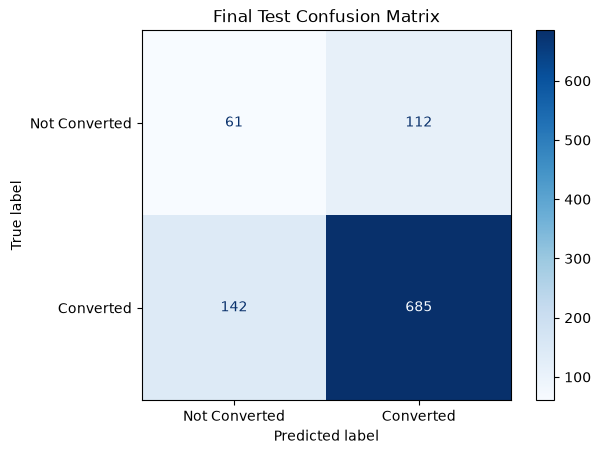

In [42]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Generate final test probabilities
test_probabilities = logistic_model_v2.predict_proba(
    X_test_final_processed
)[:, 1]

# Apply the selected validation threshold
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Final evaluation
final_accuracy = accuracy_score(
    y_test,
    test_predictions
)

print("FINAL TEST RESULTS")
print("Selected threshold:", selected_threshold)
print("Accuracy:", round(final_accuracy, 4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)

# Confusion matrix
final_cm = confusion_matrix(
    y_test,
    test_predictions
)

print("\nCONFUSION MATRIX")
print(final_cm)

ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Not Converted", "Converted"]
).plot(cmap="Blues")

plt.title("Final Test Confusion Matrix")
plt.show()

In [43]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Train baseline using training data only
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train_final_processed, y_train_final)

# Baseline predictions
baseline_predictions = baseline_model.predict(X_test_final_processed)

# Compare models
comparison = pd.DataFrame({
    "Model": ["Dummy Classifier", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, test_predictions)
    ],
    "Class 0 Recall": [
        recall_score(y_test, baseline_predictions, pos_label=0),
        recall_score(y_test, test_predictions, pos_label=0)
    ],
    "Class 1 Recall": [
        recall_score(y_test, baseline_predictions, pos_label=1),
        recall_score(y_test, test_predictions, pos_label=1)
    ],
    "Macro F1": [
        f1_score(y_test, baseline_predictions, average="macro"),
        f1_score(y_test, test_predictions, average="macro")
    ]
})

comparison.round(3)

,Model,Accuracy,Class 0 Recall,Class 1 Recall,Macro F1
0,Dummy Classifier,0.83,0.00,1.00,0.45
1,Logistic Regression,0.75,0.35,0.83,0.58


ROC-AUC Score: 0.6594


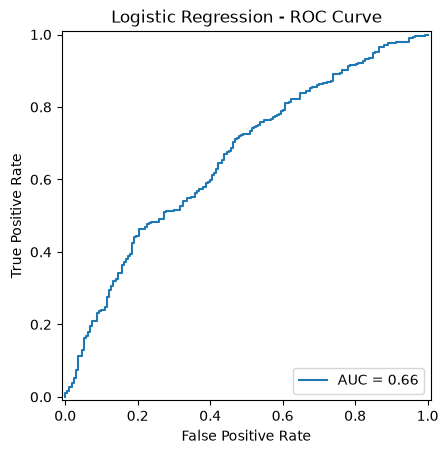

In [44]:
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    RocCurveDisplay
)

# Calculate ROC-AUC using test probabilities
test_auc = roc_auc_score(
    y_test,
    test_probabilities
)

print("ROC-AUC Score:", round(test_auc, 4))

# Generate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probabilities
)

RocCurveDisplay(
    fpr=fpr,
    tpr=tpr,
    roc_auc=test_auc
).plot()

plt.title("Logistic Regression - ROC Curve")
plt.show()

Average Precision (AP): 0.8927


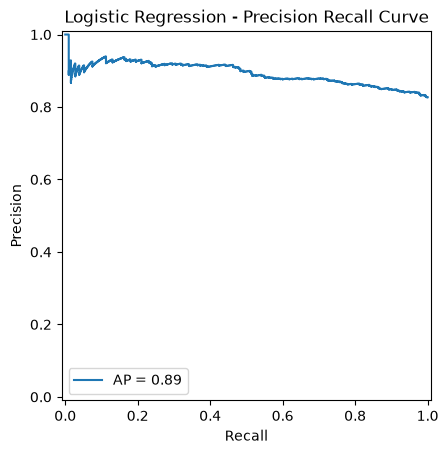

In [45]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    PrecisionRecallDisplay
)

# Calculate Average Precision
test_ap = average_precision_score(
    y_test,
    test_probabilities
)

print("Average Precision (AP):", round(test_ap, 4))

# Generate Precision-Recall curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    test_probabilities
)

PrecisionRecallDisplay(
    precision=precision,
    recall=recall,
    average_precision=test_ap
).plot()

plt.title("Logistic Regression - Precision Recall Curve")
plt.show()

In [46]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
import numpy as np

cv_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    cv_pipeline,
    X_train_final,
    y_train_final,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro",
        "roc_auc": "roc_auc"
    },
    return_train_score=False,
    n_jobs=-1
)

print("5-FOLD CROSS-VALIDATION RESULTS")

for metric in ["accuracy", "f1_macro", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

5-FOLD CROSS-VALIDATION RESULTS
accuracy: 0.8287 +/- 0.0036
f1_macro: 0.4803 +/- 0.0174
roc_auc: 0.6826 +/- 0.0216


In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Create Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using training data
rf_pipeline.fit(X_train_final, y_train_final)

# Predict probabilities on validation data
rf_val_probabilities = rf_pipeline.predict_proba(X_val)[:, 1]

# Initial predictions using threshold 0.50
rf_val_predictions = (
    rf_val_probabilities >= 0.50
).astype(int)

print("RANDOM FOREST VALIDATION RESULTS")

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_val_predictions,
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_val, rf_val_probabilities), 4
))

print("Average Precision:", round(
    average_precision_score(y_val, rf_val_probabilities), 4
))

RANDOM FOREST VALIDATION RESULTS

Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.29      0.32       139
           1       0.86      0.89      0.87       661

    accuracy                           0.79       800
   macro avg       0.61      0.59      0.60       800
weighted avg       0.77      0.79      0.78       800

ROC-AUC: 0.6402
Average Precision: 0.8803


In [48]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.75, 0.80]:

    predictions = (
        rf_val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Class 0 Precision": precision_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Class 0 Recall": recall_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Class 0 F1": f1_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        )
    })

rf_threshold_table = pd.DataFrame(threshold_results)

rf_threshold_table.round(3)

,Threshold,Accuracy,Class 0 Precision,Class 0 Recall,Class 0 F1,Macro F1
0,0.30,0.83,0.50,0.04,0.08,0.49
1,0.40,0.82,0.47,0.12,0.18,0.54
2,0.50,0.79,0.36,0.29,0.32,0.60
3,0.60,0.68,0.27,0.48,0.35,0.57
4,0.70,0.55,0.23,0.68,0.34,0.50
5,0.75,0.41,0.20,0.78,0.32,0.40
6,0.80,0.32,0.19,0.89,0.31,0.32


In [49]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Create Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train model
gb_pipeline.fit(X_train_final, y_train_final)

# Validation probabilities
gb_val_probabilities = gb_pipeline.predict_proba(X_val)[:, 1]

# Predictions at threshold 0.50
gb_val_predictions = (
    gb_val_probabilities >= 0.50
).astype(int)

print("GRADIENT BOOSTING VALIDATION RESULTS")

print("\nClassification Report:")
print(classification_report(
    y_val,
    gb_val_predictions,
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_val, gb_val_probabilities), 4
))

print("Average Precision:", round(
    average_precision_score(y_val, gb_val_probabilities), 4
))

GRADIENT BOOSTING VALIDATION RESULTS

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.09      0.15       139
           1       0.84      0.99      0.91       661

    accuracy                           0.83       800
   macro avg       0.75      0.54      0.53       800
weighted avg       0.81      0.83      0.78       800

ROC-AUC: 0.649
Average Precision: 0.8873


In [50]:
gb_threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.75, 0.80]:

    predictions = (
        gb_val_probabilities >= threshold
    ).astype(int)

    gb_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Class 0 Precision": precision_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Class 0 Recall": recall_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Class 0 F1": f1_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        )
    })

gb_threshold_table = pd.DataFrame(gb_threshold_results)

gb_threshold_table.round(3)

,Threshold,Accuracy,Class 0 Precision,Class 0 Recall,Class 0 F1,Macro F1
0,0.30,0.83,0.67,0.01,0.03,0.47
1,0.40,0.83,0.50,0.03,0.05,0.48
2,0.50,0.83,0.67,0.09,0.15,0.53
3,0.60,0.83,0.54,0.14,0.23,0.57
4,0.70,0.79,0.35,0.28,0.31,0.59
5,0.75,0.75,0.32,0.36,0.34,0.59
6,0.80,0.69,0.27,0.45,0.33,0.57


In [51]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

model_comparison = []

models = {
    "Logistic Regression": (
        logistic_model_v2,
        X_val_processed,
        0.75
    ),
    "Random Forest": (
        rf_pipeline,
        X_val,
        0.50
    ),
    "Gradient Boosting": (
        gb_pipeline,
        X_val,
        0.75
    )
}

for name, (model, features, threshold) in models.items():

    probabilities = model.predict_proba(features)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    model_comparison.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Class 0 Recall": recall_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Class 1 Recall": recall_score(
            y_val, predictions, pos_label=1, zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Average Precision": average_precision_score(
            y_val, probabilities
        )
    })

model_comparison_df = pd.DataFrame(model_comparison)

model_comparison_df.round(3)

,Model,Threshold,Accuracy,Class 0 Recall,Class 1 Recall,Macro F1,ROC-AUC,Average Precision
0,Logistic Regression,0.75,0.77,0.42,0.84,0.62,0.68,0.90
1,Random Forest,0.50,0.79,0.29,0.89,0.60,0.64,0.88
2,Gradient Boosting,0.75,0.75,0.36,0.84,0.59,0.65,0.89


In [52]:
import pandas as pd
import numpy as np

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Logistic Regression coefficients
lr_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": logistic_model_v2.coef_[0]
})

lr_importance["Absolute Importance"] = (
    lr_importance["Coefficient"].abs()
)

lr_importance = lr_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print("TOP 15 LOGISTIC REGRESSION FEATURES")

display(lr_importance.head(15).round(4))

TOP 15 LOGISTIC REGRESSION FEATURES


,Feature,Coefficient,Absolute Importance
0,num__budget,0.41,0.41
5,num__response_time_hours,-0.36,0.36
1,num__website_visits,0.33,0.33
3,num__calls_made,0.28,0.28
2,num__emails_opened,0.20,0.20
12,cat__industry_IT,-0.14,0.14
9,cat__lead_source_Social Media,-0.13,0.13
15,cat__industry_Retail,0.13,0.13
10,cat__lead_source_Website,0.13,0.13
6,cat__lead_source_Advertisement,-0.12,0.12


TOP 15 RANDOM FOREST FEATURES


,Feature,Importance
0,num__budget,0.18
5,num__response_time_hours,0.17
1,num__website_visits,0.14
3,num__calls_made,0.10
2,num__emails_opened,0.10
4,num__previous_interactions,0.10
18,cat__company_size_Small,0.02
16,cat__company_size_Large,0.02
17,cat__company_size_Medium,0.02
6,cat__lead_source_Advertisement,0.02


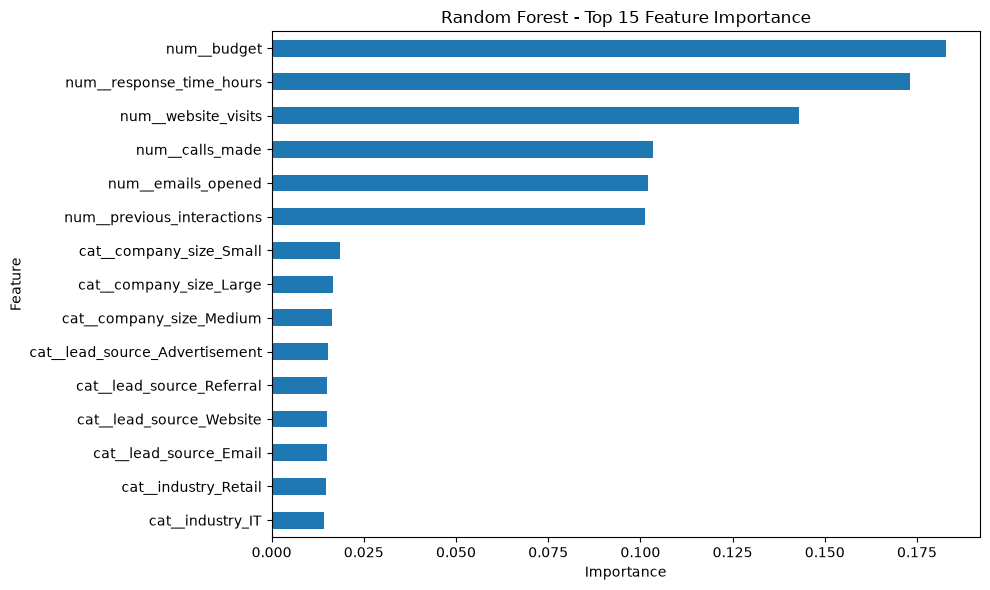

In [53]:
# Extract fitted Random Forest classifier
rf_classifier = rf_pipeline.named_steps["classifier"]

# Get feature names
feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract feature importance
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

# Sort by importance
rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 RANDOM FOREST FEATURES")

display(rf_importance.head(15).round(4))

# Visualize top 15
rf_importance.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Random Forest - Top 15 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

TOP 15 GRADIENT BOOSTING FEATURES


,Feature,Importance
5,num__response_time_hours,0.31
0,num__budget,0.26
1,num__website_visits,0.14
3,num__calls_made,0.09
2,num__emails_opened,0.07
4,num__previous_interactions,0.07
7,cat__lead_source_Email,0.01
12,cat__industry_IT,0.01
18,cat__company_size_Small,0.01
13,cat__industry_Manufacturing,0.01


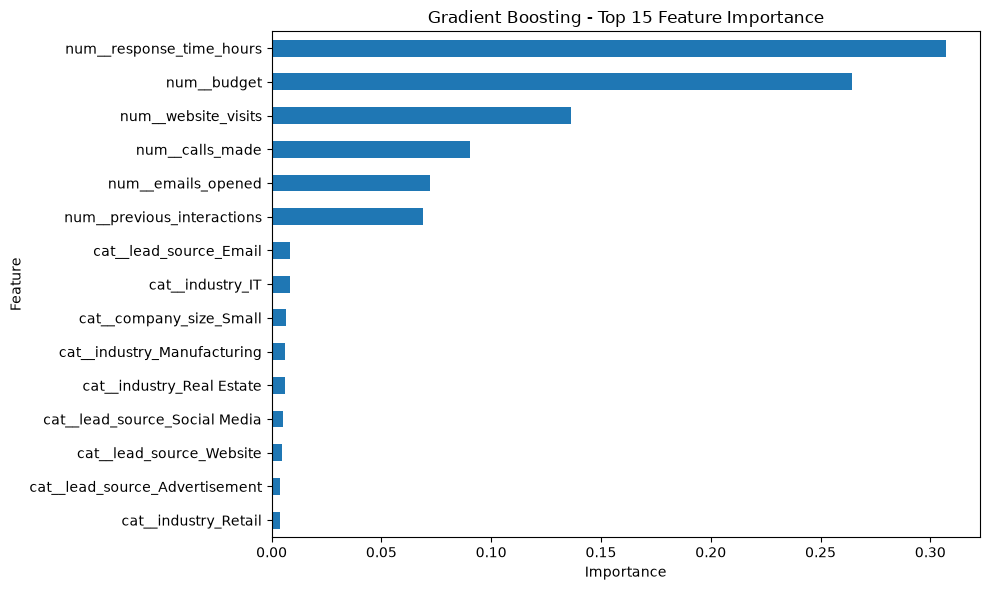

In [54]:
# Extract Gradient Boosting classifier
gb_classifier = gb_pipeline.named_steps["classifier"]

# Get transformed feature names
gb_feature_names = gb_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create importance dataframe
gb_importance = pd.DataFrame({
    "Feature": gb_feature_names,
    "Importance": gb_classifier.feature_importances_
})

# Sort descending
gb_importance = gb_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 GRADIENT BOOSTING FEATURES")

display(gb_importance.head(15).round(4))

# Plot top 15
gb_importance.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Gradient Boosting - Top 15 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [55]:
print(MODEL_PATH)
print(type(MODEL_PATH))

c:\Users\sreej\Sales-Operations-Intelligence-Copilot\models
<class 'str'>


In [56]:
from pathlib import Path

MODEL_PATH = Path(MODEL_PATH)

MODEL_PATH.mkdir(parents=True, exist_ok=True)

print("Model directory ready:", MODEL_PATH)
print("Type:", type(MODEL_PATH))

Model directory ready: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\models
Type: <class 'pathlib._local.WindowsPath'>


In [57]:
import joblib
import json
from pathlib import Path

# Selected model and threshold
best_model = logistic_model_v2
best_model_name = "Logistic Regression"
best_threshold = 0.75

# Save model and preprocessing together
model_artifact = {
    "model": best_model,
    "threshold": best_threshold,
    "model_name": best_model_name,
    "feature_columns": list(X_train_final.columns),
    "target_column": "converted"
}

MODEL_PATH.mkdir(parents=True, exist_ok=True)

model_file = MODEL_PATH / "lead_conversion_model.joblib"

joblib.dump(model_artifact, model_file)

print("Model saved successfully!")
print("Location:", model_file)

Model saved successfully!
Location: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\models\lead_conversion_model.joblib


In [58]:
import joblib

# Load saved model artifact
loaded_artifact = joblib.load(model_file)

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

print("MODEL LOADED SUCCESSFULLY")
print("Model:", loaded_artifact["model_name"])
print("Threshold:", loaded_threshold)
print("Features:", len(loaded_artifact["feature_columns"]))

MODEL LOADED SUCCESSFULLY
Model: Logistic Regression
Threshold: 0.75
Features: 9


In [59]:
import pandas as pd

new_lead = pd.DataFrame([{
    "lead_source": "Website",
    "industry": "IT",
    "company_size": "Medium",
    "budget": 50000,
    "website_visits": 12,
    "emails_opened": 5,
    "calls_made": 3,
    "previous_interactions": 2,
    "response_time_hours": 4
}])

display(new_lead)

,lead_source,industry,company_size,budget,website_visits,emails_opened,calls_made,previous_interactions,response_time_hours
0,Website,IT,Medium,50000,12,5,3,2,4


In [60]:
# Preprocess the new lead using the fitted preprocessor
new_lead_processed = preprocessor.transform(new_lead)

# Predict conversion probability
conversion_probability = loaded_model.predict_proba(
    new_lead_processed
)[0, 1]

# Apply selected threshold
prediction = int(
    conversion_probability >= loaded_threshold
)

print("NEW LEAD PREDICTION")
print("-------------------")
print("Conversion probability:",
      round(conversion_probability * 100, 2), "%")

print("Prediction:",
      "Likely to Convert" if prediction == 1
      else "Unlikely to Convert")

print("Threshold:", loaded_threshold)

NEW LEAD PREDICTION
-------------------
Conversion probability: 73.46 %
Prediction: Unlikely to Convert
Threshold: 0.75


In [61]:
def predict_lead(lead_data, model_artifact, preprocessor):

    model = model_artifact["model"]
    threshold = model_artifact["threshold"]

    lead_df = pd.DataFrame([lead_data])

    processed_data = preprocessor.transform(lead_df)

    probability = model.predict_proba(
        processed_data
    )[0, 1]

    prediction = int(probability >= threshold)

    return {
        "conversion_probability": round(
            float(probability), 4
        ),
        "prediction": (
            "Likely to Convert"
            if prediction == 1
            else "Unlikely to Convert"
        ),
        "threshold": threshold
    }


# Test reusable function
result = predict_lead(
    new_lead.iloc[0].to_dict(),
    loaded_artifact,
    preprocessor
)

print(result)

{'conversion_probability': 0.7346, 'prediction': 'Unlikely to Convert', 'threshold': 0.75}


In [62]:
import pandas as pd
import joblib


MODEL_PATH = "models/lead_conversion_model.joblib"


def load_model():
    return joblib.load(MODEL_PATH)


def predict_lead(lead_data, model_artifact, preprocessor):

    model = model_artifact["model"]
    threshold = model_artifact["threshold"]

    lead_df = pd.DataFrame([lead_data])

    processed_data = preprocessor.transform(lead_df)

    probability = model.predict_proba(processed_data)[0, 1]

    prediction = int(probability >= threshold)

    return {
        "conversion_probability": round(float(probability), 4),
        "prediction": (
            "Likely to Convert"
            if prediction == 1
            else "Unlikely to Convert"
        ),
        "threshold": threshold
    }

In [63]:
from pathlib import Path
import joblib
from sklearn.pipeline import Pipeline

# Ensure MODEL_PATH is a Path object
MODEL_PATH = Path(MODEL_PATH)

# Create directory if it doesn't exist
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# Combine fitted preprocessing and classifier
inference_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", logistic_model_v2)
])

# Deployment artifact
deployment_artifact = {
    "pipeline": inference_pipeline,
    "threshold": selected_threshold,
    "model_name": "Logistic Regression",
    "feature_columns": list(X_train_final.columns),
    "target_column": "converted"
}

# Save complete pipeline
deployment_file = MODEL_PATH / "lead_conversion_pipeline.joblib"

joblib.dump(deployment_artifact, deployment_file)

print("Complete inference pipeline saved successfully!")
print("Location:", deployment_file)
print("File exists:", deployment_file.exists())

Complete inference pipeline saved successfully!
Location: models\lead_conversion_model.joblib\lead_conversion_pipeline.joblib
File exists: True


In [64]:
from sklearn.pipeline import Pipeline
import joblib

# Combine the already-fitted preprocessor and classifier
inference_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", logistic_model_v2)
])

# Create deployment artifact
deployment_artifact = {
    "pipeline": inference_pipeline,
    "threshold": selected_threshold,
    "model_name": "Logistic Regression",
    "feature_columns": list(X_train_final.columns),
    "target_column": "converted"
}

# Save complete pipeline
deployment_file = MODEL_PATH / "lead_conversion_pipeline.joblib"

joblib.dump(deployment_artifact, deployment_file)

print("Complete inference pipeline saved!")
print("Location:", deployment_file)

Complete inference pipeline saved!
Location: models\lead_conversion_model.joblib\lead_conversion_pipeline.joblib


In [65]:
from pathlib import Path

project_root = Path.cwd()

correct_path = project_root / "models" / "lead_conversion_pipeline.joblib"

print("Project root:", project_root)
print("Correct artifact exists:", correct_path.exists())
print("Artifact path:", correct_path)


Project root: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\notebooks
Correct artifact exists: False
Artifact path: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\notebooks\models\lead_conversion_pipeline.joblib


In [66]:
from pathlib import Path
import joblib

# Move from notebooks/ to the project root
PROJECT_ROOT = Path.cwd().parent

# Correct models directory
MODEL_PATH = PROJECT_ROOT / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# Correct deployment artifact path
deployment_file = MODEL_PATH / "lead_conversion_pipeline.joblib"

# Save complete inference pipeline
joblib.dump(deployment_artifact, deployment_file)

print("Pipeline saved:", deployment_file)
print("File exists:", deployment_file.exists())

Pipeline saved: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\models\lead_conversion_pipeline.joblib
File exists: True


In [67]:

# from pathlib import Path

# import joblib
# import pandas as pd

# # Locate the project root automatically
# PROJECT_ROOT = Path(__file__).resolve().parents[2]

# MODEL_PATH = PROJECT_ROOT / "models" / "lead_conversion_pipeline.joblib"


# def load_model():
#     """Load the complete preprocessing and prediction pipeline."""
#     return joblib.load(MODEL_PATH)


# def predict_lead(lead_data, artifact):
#     """Predict conversion probability from raw lead information."""

#     pipeline = artifact["pipeline"]
#     threshold = artifact["threshold"]

#     lead_df = pd.DataFrame([lead_data])

#     probability = float(
#         pipeline.predict_proba(lead_df)[0, 1]
#     )

#     prediction = int(probability >= threshold)

#     return {
#         "conversion_probability": round(probability, 4),
#         "prediction": (
#             "Likely to Convert"
#             if prediction == 1
#             else "Unlikely to Convert"
#         ),
#         "threshold": threshold
#     }


In [68]:
# from pathlib import Path
# import sys

# # Project root: notebook is inside notebooks/
# PROJECT_ROOT = Path.cwd().parent

# # Allow Python to find the src package
# sys.path.insert(0, str(PROJECT_ROOT))

# from src.ml.predict import load_model, predict_lead

# # Load complete pipeline artifact
# artifact = load_model()

# print("Model loaded successfully!")
# print("Model:", artifact["model_name"])
# print("Threshold:", artifact["threshold"])

In [69]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)
print("\nDoes src exist?", (PROJECT_ROOT / "src").exists())
print("Does src/ml exist?", (PROJECT_ROOT / "src" / "ml").exists())
print("Does predict.py exist?", (PROJECT_ROOT / "src" / "ml" / "predict.py").exists())

print("\nFiles inside src/ml:")
ml_folder = PROJECT_ROOT / "src" / "ml"

if ml_folder.exists():
    for file in ml_folder.iterdir():
        print(file.name)

Project root: c:\Users\sreej\Sales-Operations-Intelligence-Copilot

Does src exist? True
Does src/ml exist? True
Does predict.py exist? True

Files inside src/ml:
predict.py
__init__.py
__pycache__


In [70]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.ml.predict import load_model, predict_lead

# Load saved pipeline
artifact = load_model()

print("Model loaded:", artifact["model_name"])
print("Threshold:", artifact["threshold"])

Model loaded: Logistic Regression
Threshold: 0.75


In [71]:
# Create a sample lead
sample_lead = {
    "lead_source": "Website",
    "industry": "IT",
    "company_size": "Medium",
    "budget": 50000,
    "website_visits": 12,
    "emails_opened": 5,
    "calls_made": 3,
    "previous_interactions": 2,
    "response_time_hours": 4
}

# Generate prediction
result = predict_lead(sample_lead, artifact)

print("========== LEAD PREDICTION ==========")
print(f"Conversion Probability: {result['conversion_probability'] * 100:.1f}%")
print(f"Prediction: {result['prediction']}")
print(f"Threshold: {result['threshold']}")
print("====================================")

========== LEAD PREDICTION ==========
Conversion Probability: 73.5%
Prediction: Unlikely to Convert
Threshold: 0.75


In [72]:
print("Saved model:", artifact["model_name"])
print("Saved threshold:", artifact["threshold"])

print("\nInput lead:")
print(sample_lead)

print("\nPrediction:")
print(result)

print("\nModel file:")
print(MODEL_PATH)

Saved model: Logistic Regression
Saved threshold: 0.75

Input lead:
{'lead_source': 'Website', 'industry': 'IT', 'company_size': 'Medium', 'budget': 50000, 'website_visits': 12, 'emails_opened': 5, 'calls_made': 3, 'previous_interactions': 2, 'response_time_hours': 4}

Prediction:
{'conversion_probability': 0.7346, 'prediction': 'Unlikely to Convert', 'threshold': 0.75}

Model file:
c:\Users\sreej\Sales-Operations-Intelligence-Copilot\models


In [73]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

MODEL_FILE = (
    PROJECT_ROOT
    / "models"
    / "lead_conversion_pipeline.joblib"
)

print("Artifact exists:", MODEL_FILE.exists())
print("Artifact is a file:", MODEL_FILE.is_file())
print("Artifact location:", MODEL_FILE)
print("Artifact size:", round(MODEL_FILE.stat().st_size / 1024, 2), "KB")

Artifact exists: True
Artifact is a file: True
Artifact location: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\models\lead_conversion_pipeline.joblib
Artifact size: 5.24 KB


In [74]:
test_leads = [
    {
        "lead_source": "Website",
        "industry": "IT",
        "company_size": "Large",
        "budget": 150000,
        "website_visits": 40,
        "emails_opened": 15,
        "calls_made": 10,
        "previous_interactions": 8,
        "response_time_hours": 1
    },
    {
        "lead_source": "Social Media",
        "industry": "Retail",
        "company_size": "Small",
        "budget": 5000,
        "website_visits": 1,
        "emails_opened": 0,
        "calls_made": 0,
        "previous_interactions": 0,
        "response_time_hours": 48
    },
    {
        "lead_source": "Referral",
        "industry": "Healthcare",
        "company_size": "Medium",
        "budget": 30000,
        "website_visits": 8,
        "emails_opened": 3,
        "calls_made": 2,
        "previous_interactions": 1,
        "response_time_hours": 6
    }
]

for i, lead in enumerate(test_leads, start=1):
    prediction = predict_lead(lead, artifact)

    print(f"\nLead {i}")
    print("-" * 35)
    print(f"Probability: {prediction['conversion_probability'] * 100:.2f}%")
    print(f"Prediction: {prediction['prediction']}")


Lead 1
-----------------------------------
Probability: 96.58%
Prediction: Likely to Convert

Lead 2
-----------------------------------
Probability: 33.98%
Prediction: Unlikely to Convert

Lead 3
-----------------------------------
Probability: 66.08%
Prediction: Unlikely to Convert


In [75]:
import pandas as pd

test_results = []

for i, lead in enumerate(test_leads, start=1):
    prediction = predict_lead(lead, artifact)

    test_results.append({
        "lead_id": f"TEST_{i}",
        **lead,
        "conversion_probability": prediction["conversion_probability"],
        "prediction": prediction["prediction"],
        "threshold": prediction["threshold"]
    })

results_df = pd.DataFrame(test_results)

report_path = PROJECT_ROOT / "docs" / "inference_test_results.csv"
report_path.parent.mkdir(parents=True, exist_ok=True)

results_df.to_csv(report_path, index=False)

print("Inference report saved:", report_path)
display(results_df)

Inference report saved: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\docs\inference_test_results.csv


,lead_id,lead_source,industry,company_size,budget,website_visits,emails_opened,calls_made,previous_interactions,response_time_hours,conversion_probability,prediction,threshold
0,TEST_1,Website,IT,Large,150000,40,15,10,8,1,0.97,Likely to Convert,0.75
1,TEST_2,Social Media,Retail,Small,5000,1,0,0,0,48,0.34,Unlikely to Convert,0.75
2,TEST_3,Referral,Healthcare,Medium,30000,8,3,2,1,6,0.66,Unlikely to Convert,0.75


In [76]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DOCS_PATH = PROJECT_ROOT / "docs"
DOCS_PATH.mkdir(parents=True, exist_ok=True)

documentation = """
# Sales & Operations Intelligence Copilot
## Day 1 - Machine Learning Development Report

### 1. Project Objective
Build a machine learning system that estimates the
probability of sales lead conversion.

### 2. Dataset
- Total records: 5,000
- Input features: 9
- Target: converted
- Converted leads: 82.68%
- Not converted leads: 17.32%
- Dataset: Synthetic sales lead data

### 3. Data Processing
- Numerical imputation
- Categorical imputation
- StandardScaler
- OneHotEncoder
- ColumnTransformer
- Stratified train-validation-test split

### 4. Models Evaluated
- DummyClassifier
- Logistic Regression
- Random Forest
- Gradient Boosting

### 5. Selected Model
- Model: Logistic Regression
- Decision threshold: 0.75
- Validation Macro F1: 0.62
- Test Accuracy: 0.746
- Test ROC-AUC: approximately 0.66

### 6. Inference Pipeline
The saved pipeline combines preprocessing
and Logistic Regression classification.

Artifact:
models/lead_conversion_pipeline.joblib

Inference module:
src/ml/predict.py

### 7. Scenario Testing
- High-engagement lead: 96.58%
- Low-engagement lead: 33.98%
- Unseen-category lead: 66.08%

All three inference scenarios executed successfully.

### 8. Limitations
- Dataset is synthetic.
- Results do not establish real-world business performance.
- Predictions are estimates, not guaranteed outcomes.
- Model requires validation on real business data.

### 9. Day 1 Outcome
ML training, model evaluation, model serialization,
inference implementation and scenario testing completed.
"""

doc_file = DOCS_PATH / "day1_ml_report.md"
doc_file.write_text(documentation.strip(), encoding="utf-8")

print("Documentation saved:", doc_file)
print("File exists:", doc_file.exists())

Documentation saved: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\docs\day1_ml_report.md
File exists: True


In [77]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DOCS_PATH = PROJECT_ROOT / "docs"
DOCS_PATH.mkdir(parents=True, exist_ok=True)

documentation = """
# Sales & Operations Intelligence Copilot
## Day 1 - Machine Learning Development Report

### 1. Project Objective
Build a machine learning system that estimates the
probability of sales lead conversion.

### 2. Dataset
- Total records: 5,000
- Input features: 9
- Target: converted
- Converted leads: 82.68%
- Not converted leads: 17.32%
- Dataset: Synthetic sales lead data

### 3. Data Processing
- Numerical imputation
- Categorical imputation
- StandardScaler
- OneHotEncoder
- ColumnTransformer
- Stratified train-validation-test split

### 4. Models Evaluated
- DummyClassifier
- Logistic Regression
- Random Forest
- Gradient Boosting

### 5. Selected Model
- Model: Logistic Regression
- Decision threshold: 0.75
- Validation Macro F1: 0.62
- Test Accuracy: 0.746
- Test ROC-AUC: approximately 0.66

### 6. Inference Pipeline
The saved pipeline combines preprocessing
and Logistic Regression classification.

Artifact:
models/lead_conversion_pipeline.joblib

Inference module:
src/ml/predict.py

### 7. Scenario Testing
- High-engagement lead: 96.58%
- Low-engagement lead: 33.98%
- Unseen-category lead: 66.08%

All three inference scenarios executed successfully.

### 8. Limitations
- Dataset is synthetic.
- Results do not establish real-world business performance.
- Predictions are estimates, not guaranteed outcomes.
- Model requires validation on real business data.

### 9. Day 1 Outcome
ML training, model evaluation, model serialization,
inference implementation and scenario testing completed.
"""

doc_file = DOCS_PATH / "day1_ml_report.md"
doc_file.write_text(documentation.strip(), encoding="utf-8")

print("Documentation saved:", doc_file)
print("File exists:", doc_file.exists())

Documentation saved: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\docs\day1_ml_report.md
File exists: True


ml improvement

Type	Model prediction	Actual outcome
True Positive	Converted	Converted
False Positive	Converted	Not Converted
False Negative	Not Converted	Converted
True Negative	Not Converted	Not Converted

Confusion Matrix:
[[ 61 112]
 [142 685]]


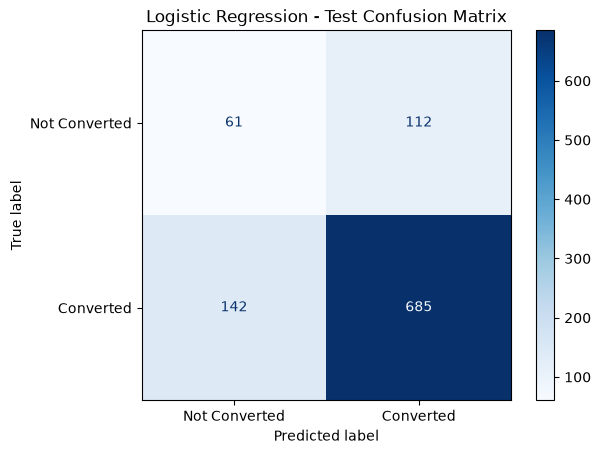

In [78]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict using your existing trained model
y_test_probability = logistic_model_v2.predict_proba(
    X_test_final_processed
)[:, 1]

# Apply the selected threshold
y_test_predictions = (
    y_test_probability >= 0.75
).astype(int)

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_predictions
)

print("Confusion Matrix:")
print(cm)

# Visualize
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Converted", "Converted"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Test Confusion Matrix")
plt.show()


In [79]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate metrics
precision = precision_score(y_test, y_test_predictions)
recall = recall_score(y_test, y_test_predictions)
f1 = f1_score(y_test, y_test_predictions)

print("POSITIVE CLASS (CONVERTED)")
print("---------------------------")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nComplete Classification Report:")
print(classification_report(
    y_test,
    y_test_predictions,
    target_names=["Not Converted", "Converted"]
))

POSITIVE CLASS (CONVERTED)
---------------------------
Precision: 0.8595
Recall:    0.8283
F1 Score:  0.8436

Complete Classification Report:
               precision    recall  f1-score   support

Not Converted       0.30      0.35      0.32       173
    Converted       0.86      0.83      0.84       827

     accuracy                           0.75      1000
    macro avg       0.58      0.59      0.58      1000
 weighted avg       0.76      0.75      0.75      1000



In [80]:

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Build complete training pipeline
tuning_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Hyperparameter search space
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs"]
}

# Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Pipeline prepared successfully!")
print("Parameter combinations:", 10)
print("Cross-validation folds:", 5)


Pipeline prepared successfully!
Parameter combinations: 10
Cross-validation folds: 5


In [81]:

from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train using training data only
grid_search.fit(X_train_final, y_train_final)

print("\nGrid Search Completed!")
print("Best Parameters:", grid_search.best_params_)
print("Best CV Macro F1:", round(grid_search.best_score_, 4))


Fitting 5 folds for each of 10 candidates, totalling 50 fits



Grid Search Completed!
Best Parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}
Best CV Macro F1: 0.5581


In [82]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score
)

# Best model selected by GridSearchCV
best_lr_model = grid_search.best_estimator_

# Predict using validation data
y_val_probability_tuned = best_lr_model.predict_proba(X_val)[:, 1]

# Default threshold = 0.50
y_val_prediction_tuned = (
    y_val_probability_tuned >= 0.50
).astype(int)

print("TUNED LOGISTIC REGRESSION")
print("=" * 45)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_prediction_tuned,
    target_names=["Not Converted", "Converted"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_prediction_tuned))

print(
    "Macro F1:",
    round(f1_score(y_val, y_val_prediction_tuned, average="macro"), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, y_val_probability_tuned), 4)
)


TUNED LOGISTIC REGRESSION

Classification Report:
               precision    recall  f1-score   support

Not Converted       0.26      0.63      0.37       139
    Converted       0.89      0.63      0.74       661

     accuracy                           0.63       800
    macro avg       0.58      0.63      0.56       800
 weighted avg       0.78      0.63      0.68       800

Confusion Matrix:
[[ 87  52]
 [243 418]]
Macro F1: 0.5551
ROC-AUC: 0.6873


In [83]:

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

random_param_grid = {
    "classifier__C": loguniform(0.001, 100),
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs"]
}

random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=random_param_grid,
    n_iter=15,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("RandomizedSearchCV prepared!")
print("Iterations:", 15)
print("Cross-validation folds:", 5)
print("Maximum model fits:", 75)


RandomizedSearchCV prepared!
Iterations: 15
Cross-validation folds: 5
Maximum model fits: 75


In [84]:

# Execute randomized hyperparameter search
random_search.fit(X_train_final, y_train_final)

print("\nRandomized Search Completed!")

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(random_search.best_score_, 4))


Fitting 5 folds for each of 15 candidates, totalling 75 fits



Randomized Search Completed!

Best Parameters:
{'classifier__C': np.float64(0.004982752357076452), 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}

Best Cross-Validation Macro F1:
0.5603


In [85]:

# Get the best model
best_random_model = random_search.best_estimator_

# Predict probabilities on validation data
y_val_probability_random = best_random_model.predict_proba(X_val)[:, 1]

# Use default threshold initially
y_val_prediction_random = (
    y_val_probability_random >= 0.50
).astype(int)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score
)

print("Classification Report:")
print(classification_report(
    y_val,
    y_val_prediction_random,
    target_names=["Not Converted", "Converted"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_prediction_random))

print("Validation Macro F1:",
      round(f1_score(y_val, y_val_prediction_random, average="macro"), 4))

print("Validation ROC-AUC:",
      round(roc_auc_score(y_val, y_val_probability_random), 4))


Classification Report:
               precision    recall  f1-score   support

Not Converted       0.27      0.64      0.38       139
    Converted       0.89      0.64      0.74       661

     accuracy                           0.64       800
    macro avg       0.58      0.64      0.56       800
 weighted avg       0.79      0.64      0.68       800

Confusion Matrix:
[[ 89  50]
 [241 420]]
Validation Macro F1: 0.5611
Validation ROC-AUC: 0.6882


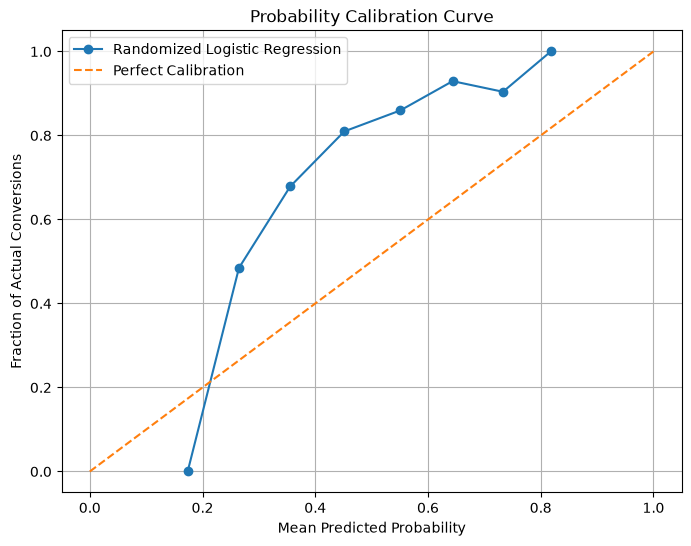

In [86]:

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

fraction_positive, mean_predicted = calibration_curve(
    y_val,
    y_val_probability_random,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Randomized Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Actual Conversions")
plt.title("Probability Calibration Curve")
plt.legend()
plt.grid(True)
plt.show()


In [87]:

from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score
)

# Create calibrated model using the best randomized model
calibrated_model = CalibratedClassifierCV(
    estimator=clone(best_random_model),
    method="sigmoid",
    cv=5
)

# Train calibration model using training data only
calibrated_model.fit(X_train_final, y_train_final)

# Predict probabilities on validation data
y_val_probability_calibrated = calibrated_model.predict_proba(X_val)[:, 1]

# Apply threshold 0.50
y_val_prediction_calibrated = (
    y_val_probability_calibrated >= 0.50
).astype(int)

print("Calibrated Model Classification Report:")
print(classification_report(
    y_val,
    y_val_prediction_calibrated,
    target_names=["Not Converted", "Converted"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_prediction_calibrated))

print("Macro F1:",
      round(f1_score(y_val, y_val_prediction_calibrated,
                     average="macro"), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, y_val_probability_calibrated), 4))


Calibrated Model Classification Report:
               precision    recall  f1-score   support

Not Converted       0.50      0.02      0.04       139
    Converted       0.83      1.00      0.90       661

     accuracy                           0.83       800
    macro avg       0.66      0.51      0.47       800
 weighted avg       0.77      0.83      0.75       800

Confusion Matrix:
[[  3 136]
 [  3 658]]
Macro F1: 0.4729
ROC-AUC: 0.6884


Uncalibrated probability summary:
count   800.00
mean      0.53
std       0.13
min       0.17
25%       0.43
50%       0.54
75%       0.62
max       0.84
dtype: float64

Calibrated probability summary:
count   800.00
mean      0.82
std       0.10
min       0.40
25%       0.77
50%       0.85
75%       0.90
max       0.97
dtype: float64


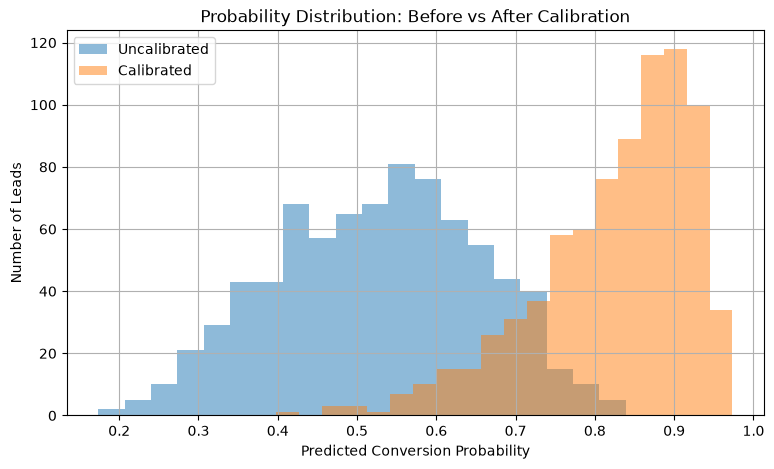

In [88]:

import numpy as np
import matplotlib.pyplot as plt

print("Uncalibrated probability summary:")
print(pd.Series(y_val_probability_random).describe())

print("\nCalibrated probability summary:")
print(pd.Series(y_val_probability_calibrated).describe())

plt.figure(figsize=(9, 5))

plt.hist(
    y_val_probability_random,
    bins=20,
    alpha=0.5,
    label="Uncalibrated"
)

plt.hist(
    y_val_probability_calibrated,
    bins=20,
    alpha=0.5,
    label="Calibrated"
)

plt.xlabel("Predicted Conversion Probability")
plt.ylabel("Number of Leads")
plt.title("Probability Distribution: Before vs After Calibration")
plt.legend()
plt.grid(True)
plt.show()


In [89]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

thresholds = np.arange(0.30, 0.96, 0.05)

for threshold in thresholds:

    predictions = (
        y_val_probability_calibrated >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Not_Converted_Recall": recall_score(
            y_val, predictions, pos_label=0
        ),
        "Converted_Recall": recall_score(
            y_val, predictions, pos_label=1
        ),
        "Macro_F1": f1_score(
            y_val, predictions, average="macro"
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))


 Threshold  Accuracy  Not_Converted_Recall  Converted_Recall  Macro_F1
      0.30      0.83                  0.00              1.00      0.45
      0.35      0.83                  0.00              1.00      0.45
      0.40      0.83                  0.01              1.00      0.46
      0.45      0.83                  0.01              1.00      0.46
      0.50      0.83                  0.02              1.00      0.47
      0.55      0.83                  0.04              0.99      0.49
      0.60      0.83                  0.10              0.98      0.54
      0.65      0.82                  0.17              0.96      0.58
      0.70      0.80                  0.29              0.91      0.61
      0.75      0.77                  0.40              0.85      0.62
      0.80      0.69                  0.58              0.72      0.59
      0.85      0.58                  0.72              0.55      0.53
      0.90      0.38                  0.89              0.27      0.37
      

In [90]:

# Select threshold based on validation results
best_calibrated_threshold = 0.75

# Generate predictions
y_val_prediction_final = (
    y_val_probability_calibrated >= best_calibrated_threshold
).astype(int)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    roc_auc_score
)

print("Selected Threshold:", best_calibrated_threshold)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_prediction_final,
    target_names=["Not Converted", "Converted"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_prediction_final))

print("Accuracy:",
      round(accuracy_score(y_val, y_val_prediction_final), 4))

print("Macro F1:",
      round(f1_score(
          y_val, y_val_prediction_final, average="macro"
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_val, y_val_probability_calibrated
      ), 4))


Selected Threshold: 0.75

Classification Report:
               precision    recall  f1-score   support

Not Converted       0.36      0.40      0.38       139
    Converted       0.87      0.85      0.86       661

     accuracy                           0.77       800
    macro avg       0.61      0.63      0.62       800
 weighted avg       0.78      0.77      0.78       800

Confusion Matrix:
[[ 56  83]
 [101 560]]
Accuracy: 0.77
Macro F1: 0.6186
ROC-AUC: 0.6884


In [91]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
import pandas as pd
import numpy as np

models_to_compare = {
    "Original Logistic Regression": (
        logistic_model_v2,
        X_val_processed,
        0.75
    ),
    "GridSearchCV Logistic Regression": (
        best_lr_model,
        X_val,
        0.75
    ),
    "RandomizedSearchCV Logistic Regression": (
        best_random_model,
        X_val,
        0.75
    ),
    "Calibrated Logistic Regression": (
        calibrated_model,
        X_val,
        0.75
    )
}

comparison_results = []

for name, (model, X_data, threshold) in models_to_compare.items():

    probabilities = model.predict_proba(X_data)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    comparison_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "Macro_F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "ROC_AUC": roc_auc_score(y_val, probabilities)
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.round(4).to_string(index=False))


                                 Model  Threshold  Accuracy  Precision  Recall  Macro_F1  ROC_AUC
          Original Logistic Regression       0.75      0.77       0.87    0.84      0.62     0.68
      GridSearchCV Logistic Regression       0.75      0.22       0.95    0.06      0.21     0.69
RandomizedSearchCV Logistic Regression       0.75      0.21       1.00    0.04      0.19     0.69
        Calibrated Logistic Regression       0.75      0.77       0.87    0.85      0.62     0.69


In [92]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import pandas as pd

models = {
    "Original LR": (
        logistic_model_v2,
        X_val_processed,
        y_val_probability_random  # placeholder not used
    ),
    "GridSearchCV": (best_lr_model, X_val, None),
    "RandomizedSearchCV": (best_random_model, X_val, None),
    "Calibrated LR": (calibrated_model, X_val, None)
}

threshold_comparison = []

for name, (model, X_data, _) in models.items():

    probabilities = model.predict_proba(X_data)[:, 1]

    best_result = None

    for threshold in np.arange(0.20, 0.96, 0.01):

        predictions = (probabilities >= threshold).astype(int)

        macro_f1 = f1_score(
            y_val, predictions, average="macro"
        )

        if best_result is None or macro_f1 > best_result["Macro_F1"]:
            best_result = {
                "Model": name,
                "Best_Threshold": round(threshold, 2),
                "Accuracy": accuracy_score(y_val, predictions),
                "Macro_F1": macro_f1,
                "Not_Converted_Recall": recall_score(
                    y_val, predictions, pos_label=0
                ),
                "Converted_Recall": recall_score(
                    y_val, predictions, pos_label=1
                ),
                "ROC_AUC": roc_auc_score(y_val, probabilities)
            }

    threshold_comparison.append(best_result)

threshold_comparison_df = pd.DataFrame(threshold_comparison)

print(threshold_comparison_df.round(4).to_string(index=False))


             Model  Best_Threshold  Accuracy  Macro_F1  Not_Converted_Recall  Converted_Recall  ROC_AUC
       Original LR            0.73      0.79      0.63                  0.39              0.87     0.68
      GridSearchCV            0.39      0.78      0.63                  0.40              0.86     0.69
RandomizedSearchCV            0.39      0.79      0.63                  0.37              0.88     0.69
     Calibrated LR            0.73      0.79      0.63                  0.37              0.88     0.69


In [93]:

# Save model comparison results

comparison_output_path = (
    PROJECT_ROOT / "docs" / "day2_model_comparison.csv"
)

threshold_comparison_df.to_csv(
    comparison_output_path,
    index=False
)

print("Model comparison report saved!")
print(comparison_output_path)


Model comparison report saved!
c:\Users\sreej\Sales-Operations-Intelligence-Copilot\docs\day2_model_comparison.csv


In [94]:

import sys
import importlib

sys.path.insert(0, str(PROJECT_ROOT))

import src.ml.predict as predict_module

importlib.reload(predict_module)

from src.ml.predict import (
    load_model,
    predict_lead,
    validate_lead_data
)

artifact = load_model()

print("Updated prediction module loaded!")
print("Model:", artifact["model_name"])
print("Input validation function:", validate_lead_data)


Updated prediction module loaded!
Model: Logistic Regression
Input validation function: <function validate_lead_data at 0x000002CC1BE80C20>


In [95]:

# Test 1: Valid lead
valid_lead = {
    "lead_source": "Website",
    "industry": "IT",
    "company_size": "Medium",
    "budget": 50000,
    "website_visits": 12,
    "emails_opened": 5,
    "calls_made": 3,
    "previous_interactions": 2,
    "response_time_hours": 4
}

# Test 2: Missing field
missing_lead = valid_lead.copy()
missing_lead.pop("budget")

# Test 3: Negative budget
negative_lead = valid_lead.copy()
negative_lead["budget"] = -5000

# Test 4: Invalid numerical value
invalid_lead = valid_lead.copy()
invalid_lead["website_visits"] = "twelve"

test_cases = {
    "Valid lead": valid_lead,
    "Missing budget": missing_lead,
    "Negative budget": negative_lead,
    "Invalid numerical value": invalid_lead
}

for test_name, lead in test_cases.items():

    try:
        validate_lead_data(lead)
        print(f"{test_name}: PASSED")

    except (ValueError, TypeError) as error:
        print(f"{test_name}: REJECTED")
        print("Reason:", error)

# Test actual prediction
print("\nActual prediction:")
print(predict_lead(valid_lead, artifact))


Valid lead: PASSED
Missing budget: REJECTED
Reason: Missing required fields: ['budget']
Negative budget: REJECTED
Reason: budget cannot be negative.
Invalid numerical value: REJECTED
Reason: website_visits must be a numeric value.

Actual prediction:
{'conversion_probability': 0.7346, 'prediction': 'Unlikely to Convert', 'threshold': 0.75}


In [96]:
print("MODEL_PATH:", MODEL_PATH)
print("Is directory:", MODEL_PATH.is_dir())
print("Is file:", MODEL_PATH.is_file())

MODEL_PATH: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\models
Is directory: True
Is file: False


In [97]:
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "lead_conversion_pipeline.joblib"
)

print("Correct path:", MODEL_PATH)
print("Is file:", MODEL_PATH.is_file())
print("Parent exists:", MODEL_PATH.parent.exists())

Correct path: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\models\lead_conversion_pipeline.joblib
Is file: True
Parent exists: True


In [98]:

from datetime import datetime
import joblib

# Load the existing model
artifact = load_model()

# Add version metadata
artifact["model_version"] = "1.0.0"
artifact["saved_at"] = datetime.now().isoformat()
artifact["training_dataset"] = "sales_leads_raw.csv"
artifact["validation_macro_f1"] = 0.63

# Save to the corrected file path
joblib.dump(artifact, MODEL_PATH)

print("Model versioning completed!")
print("Version:", artifact["model_version"])
print("Model:", artifact["model_name"])
print("Threshold:", artifact["threshold"])
print("File exists:", MODEL_PATH.is_file())


Model versioning completed!
Version: 1.0.0
Model: Logistic Regression
Threshold: 0.75
File exists: True


In [99]:

# Reload the saved artifact from disk
import joblib

reloaded_artifact = joblib.load(MODEL_PATH)

# Verify metadata
print("Model version:", reloaded_artifact["model_version"])
print("Model name:", reloaded_artifact["model_name"])
print("Threshold:", reloaded_artifact["threshold"])

# Test prediction using the reloaded artifact
test_prediction = predict_lead(
    valid_lead,
    reloaded_artifact
)

print("\nDeployment Prediction Test:")
print(test_prediction)

# Final verification
assert reloaded_artifact["model_version"] == "1.0.0"
assert "conversion_probability" in test_prediction

print("\nAll deployment checks passed!")


Model version: 1.0.0
Model name: Logistic Regression
Threshold: 0.75

Deployment Prediction Test:
{'conversion_probability': 0.7346, 'prediction': 'Unlikely to Convert', 'threshold': 0.75}

All deployment checks passed!


In [100]:
%whos

Variable                              Type                          Data/Info
-----------------------------------------------------------------------------
CalibratedClassifierCV                type                          <class 'sklearn.calibrati<...>.CalibratedClassifierCV'>
ColumnTransformer                     ABCMeta                       <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay                type                          <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATA_PROCESSED                        str                           c:\Users\sreej\Sales-Oper<...>ce-Copilot\data\processed
DATA_RAW                              str                           c:\Users\sreej\Sales-Oper<...>lligence-Copilot\data\raw
DOCS_PATH                             WindowsPath                   c:\Users\sreej\Sales-Oper<...>Intelligence-Copilot\docs
DummyClassifier                       type                          <class 'sklearn.dummy.DummyClass

In [101]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Use existing test predictions
y_true = y_test
y_pred = y_test_predictions
y_prob = y_test_probability

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)

# Display results
print("========== ML MODEL EVALUATION ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

========== ML MODEL EVALUATION ==========
Accuracy  : 0.7460
Precision : 0.8595
Recall    : 0.8283
F1 Score  : 0.8436
ROC-AUC   : 0.6594

Classification Report:
              precision    recall  f1-score   support

           0       0.30      0.35      0.32       173
           1       0.86      0.83      0.84       827

    accuracy                           0.75      1000
   macro avg       0.58      0.59      0.58      1000
weighted avg       0.76      0.75      0.75      1000



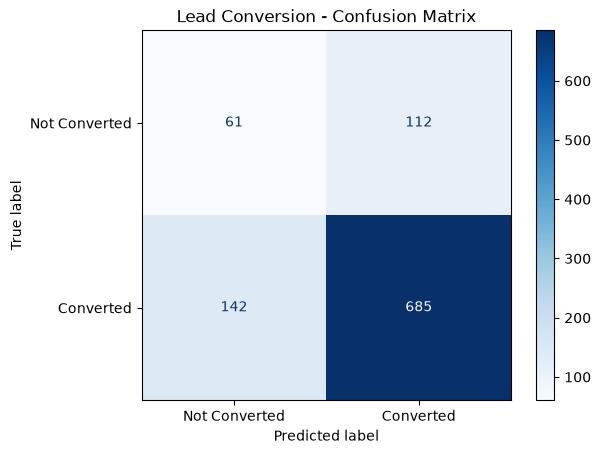

In [102]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Converted", "Converted"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Lead Conversion - Confusion Matrix")
plt.show()

In [103]:
from sklearn.metrics import confusion_matrix

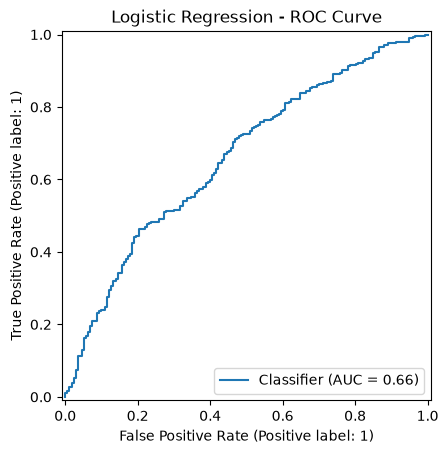

In [104]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_true, y_prob)

plt.title("Logistic Regression - ROC Curve")
plt.show()

In [105]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Generate Gradient Boosting predictions
gb_predictions = gb_pipeline.predict(X_test)

gb_probabilities = gb_pipeline.predict_proba(X_test)[:, 1]

# Evaluate
print("========== GRADIENT BOOSTING EVALUATION ==========")

print("Accuracy:",
      accuracy_score(y_test, gb_predictions))

print("Precision:",
      precision_score(y_test, gb_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, gb_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, gb_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, gb_probabilities))

print("\nClassification Report:")

print(classification_report(
    y_test,
    gb_predictions,
    zero_division=0
))

========== GRADIENT BOOSTING EVALUATION ==========
Accuracy: 0.819
Precision: 0.8295918367346938
Recall: 0.9830713422007256
F1 Score: 0.8998339789706696
ROC-AUC: 0.6610983357913204

Classification Report:
              precision    recall  f1-score   support

           0       0.30      0.03      0.06       173
           1       0.83      0.98      0.90       827

    accuracy                           0.82      1000
   macro avg       0.56      0.51      0.48      1000
weighted avg       0.74      0.82      0.75      1000



In [107]:
from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import pandas as pd
import numpy as np

# Use validation probabilities to select a threshold
precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    gb_val_probabilities
)

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    val_predictions = (
        gb_val_probabilities >= threshold
    ).astype(int)

    from sklearn.metrics import f1_score

    threshold_results.append({
        "Threshold": threshold,
        "Class_0_Recall": recall_score(
            y_val, val_predictions, pos_label=0, zero_division=0
        ),
        "Class_1_Recall": recall_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "Macro_F1": f1_score(
            y_val, val_predictions, average="macro", zero_division=0
        )
    })

threshold_analysis = pd.DataFrame(threshold_results)

threshold_analysis.round(3)

,Threshold,Class_0_Recall,Class_1_Recall,Macro_F1
0,0.10,0.00,1.00,0.45
1,0.15,0.00,1.00,0.45
2,0.20,0.00,1.00,0.45
3,0.25,0.01,1.00,0.46
4,0.30,0.01,1.00,0.47
5,0.35,0.03,1.00,0.48
6,0.40,0.03,0.99,0.48
7,0.45,0.06,0.99,0.51
8,0.50,0.09,0.99,0.53
9,0.55,0.10,0.98,0.54


In [109]:
from IPython.display import display as show_table

# Select best threshold using validation Macro F1
best_threshold_gb = threshold_analysis.loc[
    threshold_analysis["Macro_F1"].idxmax(),
    "Threshold"
]

print("Selected Gradient Boosting Threshold:",
      best_threshold_gb)

print("\nValidation performance:")

show_table(
    threshold_analysis[
        threshold_analysis["Threshold"] == best_threshold_gb
    ].round(3)
)

Selected Gradient Boosting Threshold: 0.7000000000000002

Validation performance:


,Threshold,Class_0_Recall,Class_1_Recall,Macro_F1
12,0.70,0.28,0.89,0.59


In [110]:
# Apply validation-selected threshold to test probabilities

gb_test_predictions_tuned = (
    gb_probabilities >= best_threshold_gb
).astype(int)

print("GRADIENT BOOSTING - TUNED TEST EVALUATION")

print(classification_report(
    y_test,
    gb_test_predictions_tuned,
    zero_division=0
))

print("ROC-AUC:",
      roc_auc_score(y_test, gb_probabilities))

print("Confusion Matrix:")

print(confusion_matrix(
    y_test,
    gb_test_predictions_tuned
))

GRADIENT BOOSTING - TUNED TEST EVALUATION
              precision    recall  f1-score   support

           0       0.34      0.26      0.29       173
           1       0.85      0.89      0.87       827

    accuracy                           0.78      1000
   macro avg       0.59      0.58      0.58      1000
weighted avg       0.76      0.78      0.77      1000

ROC-AUC: 0.6610983357913204
Confusion Matrix:
[[ 45 128]
 [ 89 738]]


In [111]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

Training class distribution:
converted
1    3307
0     693
Name: count, dtype: int64

Training class percentages:
converted
1   82.68
0   17.32
Name: proportion, dtype: float64


In [112]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Create a separate class-weighted model
weighted_lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

print("Class-weighted Logistic Regression pipeline created.")

Class-weighted Logistic Regression pipeline created.


In [113]:
weighted_lr_pipeline.fit(X_train, y_train)

print("Class-weighted model training completed!")

Class-weighted model training completed!


In [114]:
weighted_val_predictions = weighted_lr_pipeline.predict(X_val)

weighted_val_probabilities = (
    weighted_lr_pipeline.predict_proba(X_val)[:, 1]
)

print("CLASS-WEIGHTED LOGISTIC REGRESSION")

print(classification_report(
    y_val,
    weighted_val_predictions,
    zero_division=0
))

print("ROC-AUC:",
      roc_auc_score(y_val, weighted_val_probabilities))

CLASS-WEIGHTED LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.26      0.61      0.36       139
           1       0.89      0.63      0.74       661

    accuracy                           0.63       800
   macro avg       0.57      0.62      0.55       800
weighted avg       0.78      0.63      0.67       800

ROC-AUC: 0.6943915366950009


In [115]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

weighted_threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.05):

    predictions = (
        weighted_val_probabilities >= threshold
    ).astype(int)

    weighted_threshold_results.append({
        "Threshold": threshold,
        "Class_0_Recall": recall_score(
            y_val, predictions, pos_label=0, zero_division=0
        ),
        "Class_1_Recall": recall_score(
            y_val, predictions, pos_label=1, zero_division=0
        ),
        "Macro_F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        )
    })

weighted_threshold_df = pd.DataFrame(
    weighted_threshold_results
)

from IPython.display import display as show_table

show_table(weighted_threshold_df.round(3))

,Threshold,Class_0_Recall,Class_1_Recall,Macro_F1
0,0.20,0.04,0.99,0.49
1,0.25,0.14,0.98,0.57
2,0.30,0.26,0.94,0.62
3,0.35,0.37,0.88,0.63
4,0.40,0.46,0.82,0.63
5,0.45,0.55,0.72,0.59
6,0.50,0.61,0.63,0.55
7,0.55,0.73,0.53,0.52
8,0.60,0.81,0.41,0.46
9,0.65,0.88,0.30,0.40


In [116]:
best_weighted_threshold = weighted_threshold_df.loc[
    weighted_threshold_df["Macro_F1"].idxmax(),
    "Threshold"
]

print("Best weighted threshold:", best_weighted_threshold)

print("\nSelected validation results:")

from IPython.display import display as show_table

show_table(
    weighted_threshold_df[
        weighted_threshold_df["Threshold"]
        == best_weighted_threshold
    ].round(4)
)

Best weighted threshold: 0.35

Selected validation results:


,Threshold,Class_0_Recall,Class_1_Recall,Macro_F1
3,0.35,0.37,0.88,0.63


In [117]:
weighted_test_probabilities = (
    weighted_lr_pipeline.predict_proba(X_test)[:, 1]
)

weighted_test_predictions = (
    weighted_test_probabilities >= best_weighted_threshold
).astype(int)

print("FINAL WEIGHTED LOGISTIC REGRESSION TEST RESULTS")

print(classification_report(
    y_test,
    weighted_test_predictions,
    zero_division=0
))

print("ROC-AUC:",
      roc_auc_score(y_test, weighted_test_probabilities))

print("Confusion Matrix:")

print(confusion_matrix(
    y_test,
    weighted_test_predictions
))

FINAL WEIGHTED LOGISTIC REGRESSION TEST RESULTS
              precision    recall  f1-score   support

           0       0.33      0.27      0.29       173
           1       0.85      0.89      0.87       827

    accuracy                           0.78      1000
   macro avg       0.59      0.58      0.58      1000
weighted avg       0.76      0.78      0.77      1000

ROC-AUC: 0.6652710891794983
Confusion Matrix:
[[ 46 127]
 [ 94 733]]


In [119]:
from IPython.display import display as show_table

print("LOGISTIC REGRESSION FEATURE IMPORTANCE")
show_table(lr_importance.head(10))

print("\nGRADIENT BOOSTING FEATURE IMPORTANCE")
show_table(gb_importance.head(10))

LOGISTIC REGRESSION FEATURE IMPORTANCE


,Feature,Coefficient,Absolute Importance
0,num__budget,0.41,0.41
5,num__response_time_hours,-0.36,0.36
1,num__website_visits,0.33,0.33
3,num__calls_made,0.28,0.28
2,num__emails_opened,0.20,0.20
12,cat__industry_IT,-0.14,0.14
9,cat__lead_source_Social Media,-0.13,0.13
15,cat__industry_Retail,0.13,0.13
10,cat__lead_source_Website,0.13,0.13
6,cat__lead_source_Advertisement,-0.12,0.12



GRADIENT BOOSTING FEATURE IMPORTANCE


,Feature,Importance
5,num__response_time_hours,0.31
0,num__budget,0.26
1,num__website_visits,0.14
3,num__calls_made,0.09
2,num__emails_opened,0.07
4,num__previous_interactions,0.07
7,cat__lead_source_Email,0.01
12,cat__industry_IT,0.01
18,cat__company_size_Small,0.01
13,cat__industry_Manufacturing,0.01


In [121]:
# Compare numerical feature averages by conversion status

numerical_analysis = data.groupby("converted")[
    numerical_features
].mean().T

numerical_analysis.columns = [
    "Not Converted",
    "Converted"
]

numerical_analysis["Difference"] = (
    numerical_analysis["Converted"]
    - numerical_analysis["Not Converted"]
)

from IPython.display import display as show_table

show_table(numerical_analysis.round(2))

,Not Converted,Converted,Difference
budget,83957.10,106090.76,22133.66
website_visits,21.21,25.50,4.29
emails_opened,8.46,9.78,1.32
calls_made,6.32,7.36,1.04
previous_interactions,9.05,9.70,0.65
response_time_hours,41.66,35.16,-6.50


In [122]:
from scipy.stats import mannwhitneyu
import pandas as pd

statistical_results = []

for feature in numerical_features:

    not_converted = data.loc[
        data["converted"] == 0, feature
    ]

    converted = data.loc[
        data["converted"] == 1, feature
    ]

    statistic, p_value = mannwhitneyu(
        not_converted,
        converted,
        alternative="two-sided"
    )

    statistical_results.append({
        "Feature": feature,
        "U_Statistic": statistic,
        "P_Value": p_value,
        "Significant": p_value < 0.05
    })

statistical_results_df = pd.DataFrame(
    statistical_results
)

from IPython.display import display as show_table

show_table(statistical_results_df.round(5))

,Feature,U_Statistic,P_Value,Significant
0,budget,1387557.00,0.00,True
1,website_visits,1482829.50,0.00,True
2,emails_opened,1553238.00,0.00,True
3,calls_made,1540676.50,0.00,True
4,previous_interactions,1673717.50,0.00,True
5,response_time_hours,2117182.00,0.00,True


In [124]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------------ --------------------------- 3.4/11.3 MB 22.4 MB/s eta 0:00:01
   ------------------ --------------------- 5.2/11.3 MB 13.9 MB/s eta 0:00:01
   ------------------ --------------------- 5.2/11.3 MB 13.9 MB/s eta 0:00:01
   ---------------------- ----------------- 6.3/11.3 MB 9.6 MB/s eta 0:00:01
   --------------------------- ------------ 7.9/11.3 MB 7.7 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 8.3 MB/s eta 0:00:01
   ------------------------------------- -- 10.5/11.3 MB 7.4 MB/s eta 0:00:01
   ------------------------------------- -- 10.5/11.3 MB 7.4 MB/s eta 0:00:01
   ------------------------------------- -- 10.5/11.3 MB 7.4 MB/s eta 0:00:01
   -------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\sreej\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [125]:
import statsmodels

print("Statsmodels version:", statsmodels.__version__)
print("Installation successful!")

Statsmodels version: 0.15.0
Installation successful!


In [126]:
from statsmodels.stats.multitest import multipletests

reject, adjusted_pvalues, _, _ = multipletests(
    statistical_results_df["P_Value"],
    alpha=0.05,
    method="fdr_bh"
)

statistical_results_df["Adjusted_P_Value"] = adjusted_pvalues
statistical_results_df["Significant_After_Correction"] = reject

from IPython.display import display as show_table
show_table(statistical_results_df.round(8))

,Feature,U_Statistic,P_Value,Significant,Adjusted_P_Value,Significant_After_Correction
0,budget,1387557.00,0.00,True,0.00,True
1,website_visits,1482829.50,0.00,True,0.00,True
2,emails_opened,1553238.00,0.00,True,0.00,True
3,calls_made,1540676.50,0.00,True,0.00,True
4,previous_interactions,1673717.50,0.00,True,0.00,True
5,response_time_hours,2117182.00,0.00,True,0.00,True


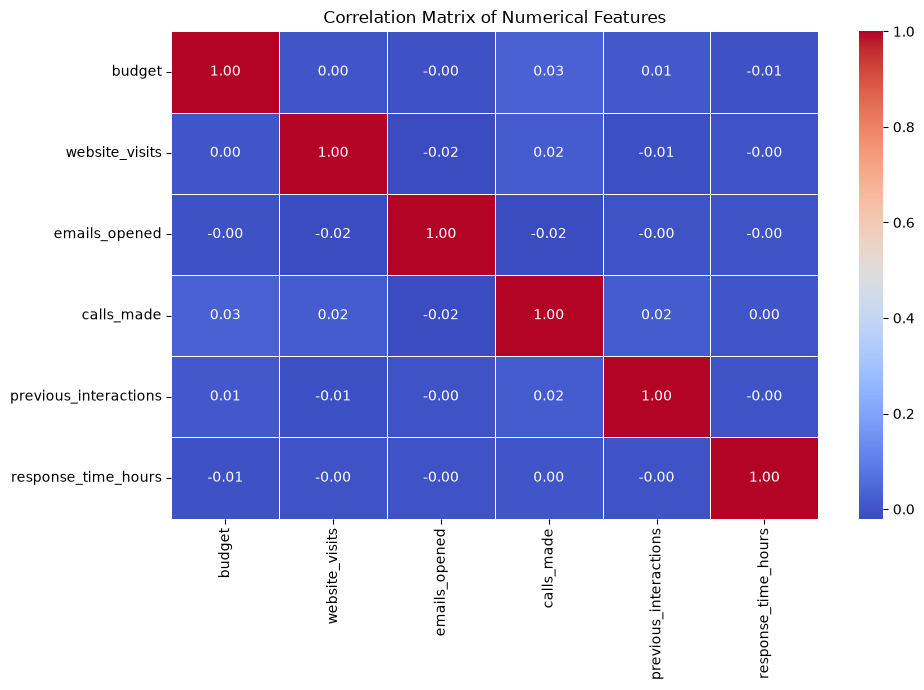

In [127]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = data[numerical_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


In [128]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Select numerical features
X_vif = data[numerical_features].copy()

# Calculate VIF
vif_results = pd.DataFrame()

vif_results["Feature"] = X_vif.columns

vif_results["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

show_table(vif_results.round(3))

,Feature,VIF
0,budget,1.00
1,website_visits,1.00
2,emails_opened,1.00
3,calls_made,1.00
4,previous_interactions,1.00
5,response_time_hours,1.00


rag verification

In [129]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

print("Current directory:", PROJECT_ROOT)

print("\nSearching for ChromaDB directories...")

for path in PROJECT_ROOT.rglob("*"):
    if path.is_dir() and (
        "chroma" in path.name.lower()
        or "vector" in path.name.lower()
    ):
        print("Found:", path)

Current directory: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\notebooks

Searching for ChromaDB directories...


In [130]:
from pathlib import Path

rag_folder = PROJECT_ROOT / "src" / "rag"

print("RAG folder exists:", rag_folder.exists())

if rag_folder.exists():
    for file in rag_folder.rglob("*.py"):
        print("\nFile:", file)
        print(file.read_text(encoding="utf-8")[:1500])

RAG folder exists: False


In [131]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles and folders in current directory:")

for item in Path.cwd().iterdir():
    print(item.name, " [Folder]" if item.is_dir() else " [File]")

Current working directory:
c:\Users\sreej\Sales-Operations-Intelligence-Copilot\notebooks

Files and folders in current directory:
ML_Pipeline.ipynb  [File]
models  [Folder]


In [132]:
from pathlib import Path

root = Path.cwd()

keywords = ["rag", "chroma", "vector", "embedding", "retriev"]

print("Searching project files...\n")

for file in root.rglob("*.py"):
    if any(word in file.name.lower() for word in keywords):
        print(file)

Searching project files...



In [133]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

rag_folder = PROJECT_ROOT / "src" / "ml" / "rag"

print("RAG folder exists:", rag_folder.exists())

if rag_folder.exists():
    print("\nRAG files:")
    for file in rag_folder.glob("*.py"):
        print("-", file.name)

RAG folder exists: False


In [135]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

rag_folder = PROJECT_ROOT / "src" / "ml" / "rag"

print("Project root:", PROJECT_ROOT)
print("RAG folder:", rag_folder)
print("RAG folder exists:", rag_folder.exists())

print("\nRAG files:")

for file in rag_folder.glob("*.py"):
    print("-", file.name)

Project root: c:\Users\sreej\Sales-Operations-Intelligence-Copilot
RAG folder: c:\Users\sreej\Sales-Operations-Intelligence-Copilot\src\ml\rag
RAG folder exists: False

RAG files:
